# Sesión 4/6 · Modelos supervisados: lineales, Naive Bayes, k-NN y SVM
**IA aplicada a la ciberseguridad · Máster en Ciberseguridad**  
**Material didáctico para principiantes · Todas las partes y retos originales resueltos.**

En esta sesión construirás detectores para distintos problemas de seguridad: estimar cuántos intentos fallidos de VPN serían normales, identificar tráfico anómalo, predecir si una conexión es un ataque, clasificar mensajes sospechosos y distinguir familias de intrusiones. El objetivo no es solo obtener una puntuación: **entender qué aprende cada algoritmo, de dónde salen sus predicciones, qué significa una métrica y cuándo desconfiar de ella**.

| Parte | Problema | Algoritmo y aprendizaje |
|:--|:--|:--|
| **A** | ¿Cuántos fallos de VPN esperaríamos? ¿Hay una anomalía? | Regresión lineal, residuos, descenso de gradiente y Ridge |
| **B** | ¿Qué probabilidad de ataque indica una conexión? | Regresión logística programada desde cero y frontera de decisión |
| **C** | ¿Cuándo merece la pena generar una alerta? | Modelo logístico sobre NSL-KDD, *odds*, falsos negativos y coste |
| **D** | ¿Parece fraudulento un mensaje? | Bolsa de palabras y Naive Bayes multinomial |
| **E** | ¿Cómo afectan las escalas y los datos al clasificador? | k vecinos, SVM lineal y SVM RBF |
| **F** | ¿De qué familia es cada ataque? | Clasificación multiclase y matriz de confusión |

**Qué datos utilizamos:** la parte A genera **120 días sintéticos** de intentos fallidos; la D usa **12 mensajes inventados**. Las partes B, C, E y F emplean **NSL-KDD**, un conjunto de conexiones de red etiquetadas. No interpretes los datos inventados como mediciones de una VPN real ni las métricas de NSL-KDD como rendimiento garantizado en producción.

## Antes de empezar · Cómo leer el notebook

Ejecuta las celdas **de arriba abajo** con `Mayús + Intro` o con «Run all» desde un kernel reiniciado. El *kernel* es el proceso de Python que guarda temporalmente las variables: si lo reinicias, tendrás que volver a ejecutar las celdas anteriores. Si cambias una celda que prepara datos o entrena un modelo, ejecuta también las que dependen de ella.

**Vocabulario mínimo, sin estadística previa:**

- Una **fila** o *muestra* es un registro: un día, una conexión o un mensaje. Una **característica** (*feature*, `X`) es algo medido sobre esa fila: duración, número de bytes, presencia de una palabra… La **etiqueta** u objetivo (`y`) es lo que queremos estimar, por ejemplo `1 = ataque` y `0 = normal`.
- **Entrenar** significa ajustar parámetros del modelo utilizando entradas con sus etiquetas. **Predecir** significa aplicar esos parámetros a una entrada. No es lo mismo ajustar con una etiqueta conocida que acertar una conexión jamás vista.
- **Entrenamiento** (`tr`) sirve para aprender; **prueba** (`te`) se reserva para medir la generalización. La **validación** es una porción aparte que permite elegir configuraciones sin consultar las etiquetas de prueba.
- Un **modelo supervisado** aprende de ejemplos etiquetados. Una **regresión** puede estimar una cantidad (fallos de VPN) o, en el caso particular de la *regresión logística*, una probabilidad de clase. Un **clasificador** transforma esa probabilidad o puntuación en una categoría.
- Un **array** de NumPy es una estructura numérica; un **DataFrame** de pandas, una tabla con columnas. Los **pipelines** encadenan preparaciones y modelos para repetir exactamente los mismos pasos al entrenar y predecir.

En las fórmulas, `n` representa el número de muestras y `p` el número de características. Verás valores medidos al ejecutar el notebook: no se anticipan números no comprobados. Las explicaciones están junto a sus resultados para evitar búsquedas entre celdas.

## Preparación · Bibliotecas, funciones auxiliares y datos

**Para qué sirve:** antes de entrenar necesitamos importar bibliotecas y cargar datos con columnas conocidas. `numpy` calcula con matrices, `pandas` maneja tablas, `matplotlib` crea gráficas y `scikit-learn` proporciona implementaciones de los algoritmos que contrastaremos con nuestros cálculos. La primera celda instala las dependencias **necesarias en esta sesión** si faltan. El original también intentaba instalar `seaborn`, `joblib`, `xgboost` y `lightgbm`; aquí se evita esa instalación innecesaria porque ninguna se usa en los cálculos de la sesión 4. Si tu entorno tiene las bibliotecas, no instala nada.

**Reproducibilidad:** las semillas (`seed` o `random_state`) fijan los números aleatorios para que puedas comparar resultados entre ejecuciones. Los tiempos de ejecución pueden variar según el ordenador, aunque los datos y predicciones se mantengan.

In [21]:
# Importar herramientas del propio Python para verificar si faltan dependencias.
import importlib.util
import subprocess
import sys
from pathlib import Path

requisitos = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
}
paquetes_ausentes = [
    nombre_pip for modulo, nombre_pip in requisitos.items()
    if importlib.util.find_spec(modulo) is None
]

print("=" * 72)
print("PREPARACIÓN · Bibliotecas de la sesión 4")
print("=" * 72)
print("Entorno:", "Google Colab" if "google.colab" in sys.modules else "Python / Jupyter")
if paquetes_ausentes:
    print("Instalación necesaria:", ", ".join(paquetes_ausentes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *paquetes_ausentes])
else:
    print("Dependencias: disponibles; no es necesario instalar nada.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

plt.rcParams["figure.figsize"] = (9, 4)
print(f"Versiones: NumPy {np.__version__} · pandas {pd.__version__} · scikit-learn {sklearn.__version__}")

PREPARACIÓN · Bibliotecas de la sesión 4
Entorno: Python / Jupyter
Dependencias: disponibles; no es necesario instalar nada.
Versiones: NumPy 2.5.5 · pandas 3.1.1 · scikit-learn 1.9.1


### Las funciones `ia_utils.py` que suministra el curso

La siguiente celda conserva **íntegro** el código auxiliar del notebook original en una cadena de texto y lo guarda en `ia_utils.py`. Es un módulo: otro archivo Python del que importaremos funciones. Contiene `load_nsl_kdd` (lee los datos), `add_category` (agrupa los ataques en familias) y generadores de datos sintéticos usados en otras sesiones. **No hay que estudiar sus casi 200 líneas ahora:** pertenecen a la infraestructura compartida. Puedes desplegar la celda si quieres inspeccionarlas.

La escritura usa `write_text`: **sobrescribe** el mismo archivo con el mismo contenido; nunca concatena funciones repetidas al ejecutar dos veces. Se llama `importlib.reload` para que, si cambiaste su código en el kernel, la importación refleje la versión actual. Este módulo no modifica `utils.py` de las sesiones anteriores.

In [22]:
# Código auxiliar original sin cambios; crear un módulo importable y recargarlo.
import importlib
IA_UTILS = '"""Funciones del curso IA aplicada a la ciberseguridad (sesiones 3 a 6)."""\nimport os, re, urllib.request\nimport numpy as np\nimport pandas as pd\n\nNSL_URL = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"\nNSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",\n  "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",\n  "root_shell","su_attempted","num_root","num_file_creations","num_shells",\n  "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",\n  "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",\n  "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",\n  "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",\n  "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",\n  "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",\n  "label","difficulty"]\n\n\ndef load_nsl_kdd(split="train", base="data"):\n    """Carga NSL-KDD y añade la columna is_attack. Descarga los ficheros si faltan."""\n    name = "KDDTrain+.txt" if split == "train" else "KDDTest+.txt"\n    path = os.path.join(base, name)\n    if not os.path.exists(path):\n        os.makedirs(base, exist_ok=True)\n        urllib.request.urlretrieve(NSL_URL + name.replace("+", "%2B"), path)\n    df = pd.read_csv(path, header=None, names=NSL_COLS)\n    df["is_attack"] = (df["label"] != "normal").astype(int)\n    return df\n\n\nATTACK_MAP = {"normal": "normal",\n  **{a: "dos" for a in ["back", "land", "neptune", "pod", "smurf", "teardrop",\n                        "apache2", "udpstorm", "processtable", "mailbomb"]},\n  **{a: "probe" for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]},\n  **{a: "r2l" for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop",\n                        "warezmaster", "warezclient", "spy", "xlock", "xsnoop",\n                        "snmpguess", "snmpgetattack", "httptunnel", "sendmail",\n                        "named", "worm"]},\n  **{a: "u2r" for a in ["buffer_overflow", "loadmodule", "rootkit", "perl",\n                        "sqlattack", "xterm", "ps"]}}\n\n\ndef add_category(df):\n    """Añade la columna category: normal, dos, probe, r2l o u2r."""\n    df["category"] = df["label"].map(ATTACK_MAP)\n    return df\n\n\ndef generar_flujos(n=60_000, frac_ataque=0.25, seed=0, cambio_herramienta=False):\n    """Flujos de red sintéticos con columnas al estilo CICIDS2017, incluidos sus defectos\n    (espacios en los nombres, infinitos, nulos y duplicados). Etiquetas BENIGN / DDoS.\n    Con cambio_herramienta=True el ataque llega en dos episodios con herramientas distintas."""\n    rng = np.random.default_rng(seed)\n    nb, na = int(n * (1 - frac_ataque)), int(n * frac_ataque)\n    t0 = pd.Timestamp("2017-07-07 09:00:00")\n    # --- tráfico benigno\n    port_b = rng.choice([443, 80, 53, 22, 8080, 3389, 0], nb, p=[.40, .20, .20, .05, .05, .02, .08])\n    port_b = np.where(port_b == 0, rng.integers(1024, 65535, nb), port_b)\n    dur_b = np.where(rng.random(nb) < 0.02, 0, rng.lognormal(11, 2, nb)).astype(int)\n    fwd_b = rng.poisson(8, nb) + 1\n    bwd_b = rng.poisson(7, nb)\n    fwl_b = np.where(rng.random(nb) < 0.15, rng.uniform(0, 10, nb), rng.normal(400, 250, nb)).clip(0)\n    bwl_b = rng.normal(700, 400, nb).clip(0)\n    syn_b = (rng.random(nb) < 0.3).astype(int)\n    win_b = rng.choice([29200, 65535, 8192, 14600, 64240, -1], nb, p=[.25, .25, .15, .1, .15, .1])\n    ts_b = rng.uniform(0, 8 * 3600, nb)\n    # --- ataque\n    if cambio_herramienta:\n        epi = rng.random(na) < 0.5\n        ts_a = np.where(epi, rng.uniform(1 * 3600, 2 * 3600, na), rng.uniform(5 * 3600, 6 * 3600, na))\n        port_a = np.where(epi, 80, rng.choice([8080, 443], na))\n        win_a = np.where(epi, 8192, rng.choice([29200, 65535, 64240], na))\n        fwl_a = np.where(epi, rng.normal(8, 6, na), rng.normal(60, 40, na)).clip(0)\n    else:\n        ts_a = rng.uniform(6.9 * 3600, 7.3 * 3600, na)\n        port_a = np.where(rng.random(na) < 0.9, 80, 443)\n        win_a = np.where(rng.random(na) < 0.95, 8192, 29200)\n        fwl_a = rng.normal(8, 6, na).clip(0)\n    dur_a = rng.lognormal(13, 1.5, na).astype(int)\n    fwd_a = rng.poisson(4, na) + 1\n    bwd_a = rng.poisson(3, na)\n    bwl_a = rng.normal(1500, 600, na).clip(0)\n    syn_a = (rng.random(na) < 0.6).astype(int)\n\n    def bloque(port, dur, fwd, bwd, fwl, bwl, syn, win, ts, label):\n        tot_f, tot_b = fwd * fwl, bwd * bwl\n        seg = np.maximum(dur, 0) / 1e6\n        with np.errstate(divide="ignore", invalid="ignore"):\n            fbs = (tot_f + tot_b) / seg\n            fps = (fwd + bwd) / seg\n            iat = np.where(fwd + bwd > 1, dur / np.maximum(fwd + bwd - 1, 1), np.nan)\n        return pd.DataFrame({\n            " Destination Port": port, " Flow Duration": dur, " Total Fwd Packets": fwd,\n            " Total Backward Packets": bwd, "Total Length of Fwd Packets": tot_f.round(1),\n            " Total Length of Bwd Packets": tot_b.round(1), " Fwd Packet Length Mean": fwl.round(2),\n            " Bwd Packet Length Mean": bwl.round(2), "Flow Bytes/s": fbs, " Flow Packets/s": fps,\n            " Flow IAT Mean": iat, " SYN Flag Count": syn, " ACK Flag Count": (rng.random(len(port)) < 0.85).astype(int),\n            "Init_Win_bytes_forward": win, " Avg Fwd Segment Size": fwl.round(2),\n            " Timestamp": t0 + pd.to_timedelta(ts, unit="s"), " Label": label})\n\n    df = pd.concat([bloque(port_b, dur_b, fwd_b, bwd_b, fwl_b, bwl_b, syn_b, win_b, ts_b, "BENIGN"),\n                    bloque(port_a, dur_a, fwd_a, bwd_a, fwl_a, bwl_a, syn_a, win_a, ts_a, "DDoS")], ignore_index=True)\n    df.loc[rng.random(len(df)) < 0.001, "Flow Bytes/s"] = np.nan\n    df = pd.concat([df, df.sample(frac=0.01, random_state=seed)], ignore_index=True)\n    return df.sort_values(" Timestamp").reset_index(drop=True)\n\n\ndef generar_authlog(ruta="auth.log", n_atacantes=12, seed=42):\n    """auth.log sintético de la sesión 2: 40 IP legítimas y n_atacantes IP de fuerza bruta (203.0.113.0/24)."""\n    import datetime as dt\n    rng = np.random.default_rng(seed); start = dt.datetime(2026, 10, 1)\n    users = ["root", "admin", "carlos", "ana", "luis", "deploy", "test", "oracle", "ubuntu", "postgres"]\n    rows = []\n    for i in range(40):\n        ip = f"10.10.10.{10 + i}"\n        for t in rng.uniform(0, 7 * 24 * 3600, rng.integers(5, 40)):\n            rows.append((start + dt.timedelta(seconds=float(t)), bool(rng.random() > 0.08), str(rng.choice(users[2:6])), ip))\n    for i in range(n_atacantes):\n        ip = f"203.0.113.{20 + i}"; t0 = rng.uniform(0, 7 * 24 * 3600 - 3600)\n        for t in t0 + np.sort(rng.uniform(0, 1800, rng.integers(60, 400))):\n            rows.append((start + dt.timedelta(seconds=float(t)), False, str(rng.choice(users)), ip))\n    rows.sort(key=lambda r: r[0])\n    with open(ruta, "w") as f:\n        for ts, ok, user, ip in rows:\n            v = "Accepted" if ok else "Failed"\n            f.write(f"{ts:%b %d %H:%M:%S} srv sshd[{rng.integers(1000, 9999)}]: {v} password "\n                    f"for {user} from {ip} port {rng.integers(1024, 65000)} ssh2\\n")\n    return ruta\n\n\ndef auth_features(ruta="auth.log"):\n    """Características por IP y ventana de 10 minutos. La columna verdad solo sirve para evaluar."""\n    pat = re.compile(r"^(\\w{3}\\s+\\d+ \\d\\d:\\d\\d:\\d\\d) \\S+ sshd\\[\\d+\\]: (Failed|Accepted) password for (\\S+) from (\\S+) port")\n    reg = []\n    for linea in open(ruta):\n        m = pat.match(linea)\n        if m:\n            reg.append((pd.to_datetime("2026 " + m.group(1), format="%Y %b %d %H:%M:%S"),\n                        m.group(2) == "Accepted", m.group(3), m.group(4)))\n    log = pd.DataFrame(reg, columns=["ts", "ok", "user", "ip"])\n    log["win"] = log["ts"].dt.floor("10min")\n    f = log.groupby(["ip", "win"]).agg(n=("ok", "size"), n_ok=("ok", "sum"), n_users=("user", "nunique")).reset_index()\n    f["n_fail"] = f["n"] - f["n_ok"]\n    f["fail_ratio"] = f["n_fail"] / f["n"]\n    f["verdad"] = f["ip"].str.startswith("203.0.113.").astype(int)\n    return f\n'
Path("ia_utils.py").write_text(IA_UTILS, encoding="utf-8")
import ia_utils
importlib.reload(ia_utils)
from ia_utils import load_nsl_kdd, add_category
print("Módulo ia_utils.py creado y cargado correctamente.")

Módulo ia_utils.py creado y cargado correctamente.


### Cargar NSL-KDD y reconocer las dos etiquetas

`load_nsl_kdd("train")` carga `data/KDDTrain+.txt`; `load_nsl_kdd("test")` hace lo mismo con `data/KDDTest+.txt`. **Solo intenta descargarlos si no existen**. Si tu entorno no tiene Internet, coloca los dos `.txt` dentro de una carpeta `data` junto al notebook antes de ejecutar. Si falla la descarga, no deben inventarse datos para simular resultados de NSL-KDD.

Cada fila representa una **conexión de red** y contiene atributos como duración, bytes o indicadores de error. `label` guarda el nombre original (`normal`, `neptune`, etc.). La utilidad crea `is_attack`: **`0` si `label == "normal"` y `1` en los demás casos**. Este objetivo es binario, aunque más adelante volveremos a usar las categorías originales para distinguir ataques. Los archivos de entrenamiento y prueba son **particiones originales distintas**, no divisiones aleatorias hechas por nosotros.

In [23]:
# Mantener train y test separados: las etiquetas de test no se utilizan para ajustar modelos.
try:
    tr = load_nsl_kdd("train")
    te = load_nsl_kdd("test")
except Exception as error:
    print("ERROR AL CARGAR NSL-KDD: faltan los archivos de entrenamiento o prueba.")
    print("Ubícalos en data/KDDTrain+.txt y data/KDDTest+.txt, o habilita la descarga.")
    raise RuntimeError("No se puede continuar con los modelos de NSL-KDD sin datos reales.") from error

# Resumen de la procedencia y del equilibrio entre ambas clases.
resumen_datos = pd.DataFrame({
    "Partición": ["Entrenamiento", "Prueba"],
    "Conexiones (filas)": [len(tr), len(te)],
    "Columnas (incluye etiquetas)": [tr.shape[1], te.shape[1]],
    "Normal (0)": [(tr["is_attack"] == 0).sum(), (te["is_attack"] == 0).sum()],
    "Ataque (1)": [(tr["is_attack"] == 1).sum(), (te["is_attack"] == 1).sum()],
    "% ataques": [100 * tr["is_attack"].mean(), 100 * te["is_attack"].mean()],
})
print("=" * 72)
print("DATOS REALES · NSL-KDD")
print("=" * 72)
display(resumen_datos)
print("Ejemplos de características disponibles:", ", ".join(tr.columns[:7]), "...")
print("Separación: train ajusta los modelos; test permite evaluar conexiones no utilizadas en el ajuste.")

DATOS REALES · NSL-KDD


,Partición,Conexiones (filas),Columnas (incluye etiquetas),Normal (0),Ataque (1),% ataques
0,Entrenamiento,125973,44,67343,58630,46.541719
1,Prueba,22544,44,9711,12833,56.924237


Ejemplos de características disponibles: duration, protocol_type, service, flag, src_bytes, dst_bytes, land ...
Separación: train ajusta los modelos; test permite evaluar conexiones no utilizadas en el ajuste.


**Cómo interpretar la tabla:** «Conexiones» es el número de observaciones; «% ataques» = `100 × n.º de conexiones de ataque / n.º total`. Si una partición tiene 40 % de ataques, no significa que 40 % del tráfico de tu empresa sea malicioso: esa proporción corresponde **solo a este dataset**. Entrenamiento y prueba pueden contener comportamientos o familias de ataques diferentes. Por eso una puntuación excelente en entrenamiento no basta para afirmar que el modelo funcionará en situaciones nuevas.

---
## Parte A · Regresión lineal: predecir lo normal y detectar desviaciones

**Problema:** en una VPN esperamos un número de intentos de autenticación fallidos cada día. Aunque las cifras fluctúen, quizá existe una **tendencia ascendente** y un descenso en fin de semana. Si aprendemos ese comportamiento, un incremento muy grande puede ser una **anomalía** que merece investigación.

Construiremos **120 días ficticios** con tres ingredientes: `200` fallos de partida, `+1,5` fallos esperados por cada día transcurrido y `−60` fallos en los días marcados como fin de semana. Añadiremos ruido aleatorio (variaciones normales, de magnitud típica cercana a 15) y **400 fallos adicionales el día 100** para simular un ataque. Los días se enumeran de `0` a `119`; el día 100 es un índice, no una fecha.

La regresión lineal propone una suma de contribuciones:

\[
\widehat{y}=b+w_{día}\cdot día+w_{finde}\cdot finde
\]

Aquí `ŷ` es el número **predicho** de fallos, `b` la base cuando las características valen cero, `w_día` el aumento por día, y `w_finde` la diferencia entre fin de semana (`1`) y laborable (`0`). Ejemplo: con `b = 200`, `w_día = 1,5`, `w_finde = −60`, para el día `10` laborable se esperan `215` fallos; si fuese fin de semana, `155`. El modelo aprende estos números de los ejemplos, no recibe los valores verdaderos ya dados.

**Dos ajustes diferentes en el código:** primero resolveremos la ecuación normal con los 120 días para ilustrar álgebra matricial. **Ese ajuste incluye el ataque y no debe utilizarse para detectarlo**. El detector real se entrena **solo con los días 0–89** y predice el periodo 90–119, donde se encuentra el día 100.

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Misma generación original: semilla=1, 120 días, fines de semana y ataque en día 100.
rng_vpn = np.random.default_rng(1)
dias_vpn = np.arange(120)
finde_vpn = (dias_vpn % 7 >= 5).astype(int)  # 1 para los días 5 y 6 de cada bloque de 7.
fallos_vpn = 200 + 1.5 * dias_vpn - 60 * finde_vpn + rng_vpn.normal(0, 15, 120)
fallos_vpn[100] += 400  # Dato sintético de ataque, ausente del entrenamiento posterior.

# X: dos columnas de entrada (día y fin de semana); y: número de fallos observado.
X_vpn = np.c_[dias_vpn, finde_vpn]

# Demostración algebraica: añadir una columna de unos permite estimar el intercepto b.
# np.linalg.solve resuelve (XᵀX)w = Xᵀy sin invertir explícitamente la matriz.
# Advertencia: esta demostración ajusta usando TODOS los días, incluido el ataque.
X_vpn_con_unos = np.c_[np.ones(len(X_vpn)), X_vpn]
pesos_todos_dias = np.linalg.solve(
    X_vpn_con_unos.T @ X_vpn_con_unos,
    X_vpn_con_unos.T @ fallos_vpn,
)

# Corte TEMPORAL: no mezclamos futuro y pasado al detectar el día 100.
X_vpn_train, X_vpn_test = X_vpn[:90], X_vpn[90:]
y_vpn_train, y_vpn_test = fallos_vpn[:90], fallos_vpn[90:]
modelo_vpn = LinearRegression().fit(X_vpn_train, y_vpn_train)
pred_vpn_test = modelo_vpn.predict(X_vpn_test)

# Medidas del error de predicción, en el conjunto FUTURO (días 90 a 119).
mae_vpn = mean_absolute_error(y_vpn_test, pred_vpn_test)
rmse_vpn = mean_squared_error(y_vpn_test, pred_vpn_test) ** 0.5
r2_vpn = r2_score(y_vpn_test, pred_vpn_test)

print("=" * 74)
print("A.1 · REGRESIÓN LINEAL · Intentos fallidos de VPN por día")
print("=" * 74)
print("Ajuste con 120 días (SOLO demostración; incluye el ataque):")
for nombre, valor in zip(["Base b", "Cambio por día", "Efecto fin de semana"], pesos_todos_dias):
    print(f"  {nombre:23s}: {valor:8.2f} fallos/día (o cambio indicado)")
print("Ajuste para DETECCIÓN (entrenado únicamente con días 0–89):")
print(f"  Base b                 : {modelo_vpn.intercept_:8.2f} fallos/día")
print(f"  Cambio por día         : {modelo_vpn.coef_[0]:8.2f} fallos/día adicional por día transcurrido")
print(f"  Efecto fin de semana   : {modelo_vpn.coef_[1]:8.2f} fallos/día de diferencia")
print("Evaluación de 30 días futuros (90–119, incluido el ataque sintético):")
print(f"  MAE  (error absoluto medio) : {mae_vpn:8.2f} fallos/día")
print(f"  RMSE (error cuadrático raíz): {rmse_vpn:8.2f} fallos/día")
print(f"  R²   (ajuste frente a media): {r2_vpn:8.3f} (sin unidades)")

A.1 · REGRESIÓN LINEAL · Intentos fallidos de VPN por día
Ajuste con 120 días (SOLO demostración; incluye el ataque):
  Base b                 :   197.59 fallos/día (o cambio indicado)
  Cambio por día         :     1.61 fallos/día (o cambio indicado)
  Efecto fin de semana   :   -66.05 fallos/día (o cambio indicado)
Ajuste para DETECCIÓN (entrenado únicamente con días 0–89):
  Base b                 :   200.84 fallos/día
  Cambio por día         :     1.48 fallos/día adicional por día transcurrido
  Efecto fin de semana   :   -62.85 fallos/día de diferencia
Evaluación de 30 días futuros (90–119, incluido el ataque sintético):
  MAE  (error absoluto medio) :    23.16 fallos/día
  RMSE (error cuadrático raíz):    72.72 fallos/día
  R²   (ajuste frente a media):    0.142 (sin unidades)


### A.1 · Cómo funcionan los parámetros y cómo leer el error

La columna de unos en `X_vpn_con_unos` representa `b`: multiplicar cualquier número por `1` deja ese número como contribución fija. El operador `@` hace una multiplicación de matrices y `.T` transpone filas y columnas. `np.linalg.solve` resuelve las **ecuaciones normales**, cuya solución minimiza la **suma de errores al cuadrado** cuando el sistema es resoluble. `LinearRegression().fit(...)` hace ese ajuste mediante una implementación de scikit-learn, sin que tengamos que resolver las ecuaciones a mano. Si los pesos calculados con **todos** los días y con **los primeros 90** difieren, parte de la diferencia se debe a que el primero ha visto el ataque.

Un **residuo** es `observado − predicho`: si hubo `310` fallos y el modelo esperaba `280`, residuo `+30`. Su signo importa: positivo significa **más intentos de los previstos**; negativo, menos. Medimos los residuos de los 30 días futuros con:

- **MAE:** media de `|residuo|`. Si los errores fueron `2` y `10`, MAE = `(2+10)/2 = 6` fallos/día. Es fácil de interpretar.
- **RMSE:** raíz de la media de `residuo²`. Con esos errores: `√((2²+10²)/2) ≈ 7,21` fallos/día. **Penaliza mucho los fallos grandes**: el día 100 puede dominarla.
- **R²:** compara el error cuadrático con el de adivinar siempre la media real de los 30 días de prueba: `1 − SSE_modelo/SSE_media`. `1` = predicción perfecta; `0` = tan bien como esa media; **puede ser negativo** = peor que ese referente. No es una probabilidad ni un «porcentaje de precisión».

Una evaluación con el ataque incluido **no representa exclusivamente la calidad al predecir días normales**. El gran error del día 100 puede ser precisamente la señal que queremos detectar.

A.2 · DETECCIÓN DE ANOMALÍAS · Umbral aprendido sin mirar el futuro
Dispersión de residuos normales (entrenamiento): 12.51 fallos/día
Límite de alerta: |residuo| > 37.54 fallos/día
Días alertados en el periodo de prueba: 1 de 30


,Fallos observados,Fallos esperados,Residuo (observado − esperado)
Día,,,
100,740.23,348.58,391.65


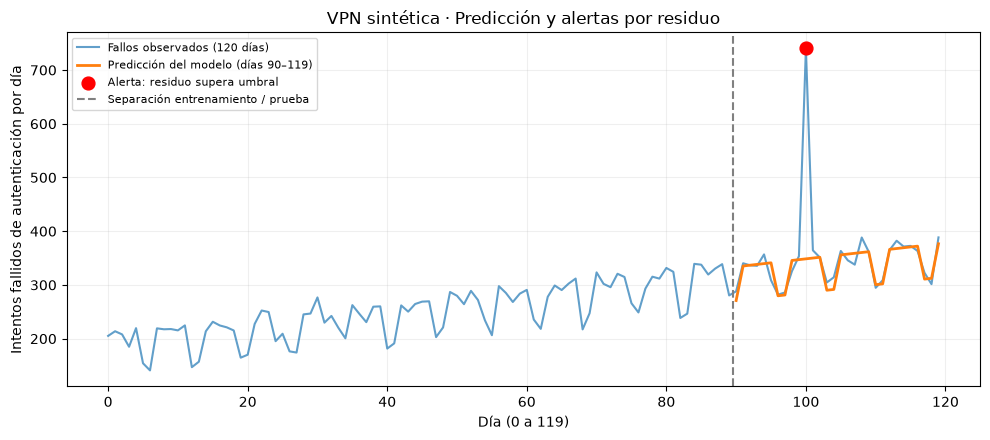

In [25]:
# El detector aprende qué desviación es habitual SOLO con residuos de entrenamiento.
residuos_vpn_train = y_vpn_train - modelo_vpn.predict(X_vpn_train)
residuos_vpn_test = y_vpn_test - pred_vpn_test

# La desviación típica resume la dispersión habitual de los residuos de entrenamiento.
# El factor 3 es una regla heurística de alerta; no equivale a una garantía estadística.
umbral_vpn = 3 * residuos_vpn_train.std()
es_anomalia_vpn = np.abs(residuos_vpn_test) > umbral_vpn

dias_alertados_vpn = dias_vpn[90:][es_anomalia_vpn]
resumen_alertas_vpn = pd.DataFrame({
    "Día": dias_alertados_vpn,
    "Fallos observados": y_vpn_test[es_anomalia_vpn],
    "Fallos esperados": pred_vpn_test[es_anomalia_vpn],
    "Residuo (observado − esperado)": residuos_vpn_test[es_anomalia_vpn],
})
print("=" * 74)
print("A.2 · DETECCIÓN DE ANOMALÍAS · Umbral aprendido sin mirar el futuro")
print("=" * 74)
print(f"Dispersión de residuos normales (entrenamiento): {residuos_vpn_train.std():.2f} fallos/día")
print(f"Límite de alerta: |residuo| > {umbral_vpn:.2f} fallos/día")
print(f"Días alertados en el periodo de prueba: {len(dias_alertados_vpn)} de {len(y_vpn_test)}")
if len(resumen_alertas_vpn):
    display(resumen_alertas_vpn.round(2).set_index("Día"))
else:
    print("No se generaron alertas con este umbral.")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(dias_vpn, fallos_vpn, label="Fallos observados (120 días)", alpha=0.7)
ax.plot(dias_vpn[90:], pred_vpn_test, label="Predicción del modelo (días 90–119)", lw=2)
ax.scatter(dias_alertados_vpn, y_vpn_test[es_anomalia_vpn],
           color="red", s=85, label="Alerta: residuo supera umbral", zorder=3)
ax.axvline(89.5, color="gray", ls="--", label="Separación entrenamiento / prueba")
ax.set(title="VPN sintética · Predicción y alertas por residuo",
       xlabel="Día (0 a 119)", ylabel="Intentos fallidos de autenticación por día")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Interpretación de A.2:** compara el número observado con la línea de predicción, **no** solo con un valor absoluto de fallos. Un día con 300 intentos puede ser normal al final de la serie y raro al principio, porque el modelo tiene una tendencia creciente. Las alertas se calculan con `|residuo|`, así que detectan incrementos **y** descensos inesperados. Revisa la tabla para comprobar si aparece el **día 100**; si aparecen otros días, serían alertas adicionales, no necesariamente ataques. Un SIEM podría aplicar una regla parecida, pero necesitaría contexto operativo, fuentes de log fiables y validación para reducir falsos avisos. El umbral `3 × desviación típica de train` es una decisión práctica, **no un hecho probado sobre los atacantes**.

### Reto avanzado A · Descenso de gradiente y regularización Ridge (resuelto)

**Enunciado original:** estandarizar las entradas, inicializar `w = 0`, hacer 500 actualizaciones de gradiente con tasas `η = 0,01`, `0,1` y `1,1`; después comparar `PolynomialFeatures(degree=15)` + `Ridge(alpha)` con `α = 0,01`, `1` y `100` mediante RMSE de train y test.

**Intuición del descenso de gradiente:** imaginamos una superficie de error. Los **pesos** `w` y la **base** `b` indican el punto donde estamos; el **gradiente** señala la dirección de máxima subida. Para reducir el error avanzamos en la dirección contraria, con un paso de tamaño `η` (*learning rate*). El error cuadrático medio es `MSE = (1/n) × Σ(predicho−real)²`. Para las entradas `X` estandarizadas, la actualización pedida es:

\[
w \leftarrow w-\eta\frac{2}{n}X^T(Xw+b-y),\qquad
b\leftarrow b-\eta\frac{2}{n}\sum_{i=1}^{n}(X_iw+b-y_i).
\]

**Estandarizar** significa `(valor − media_train) / desviación_train`. Se hace porque `día` varía entre 0 y 89, mientras `finde` vale 0 o 1; una escala descompensada dificulta elegir `η`. Ajustamos media y dispersión **solo con train**. Un `η` pequeño puede avanzar lentamente; uno excesivo puede rebotar y aumentar el error hasta divergir. La celda interrumpe una prueba si los valores se disparan: evita llenar el notebook de infinitos, **sin cambiar la fórmula de actualización**.

A.3 · RETO · Velocidad y estabilidad del descenso de gradiente


,Iteraciones realizadas,MSE inicial (fallos²),MSE final (fallos²),Estado
η (tasa de aprendizaje),,,,
0.01,500,64418.571,1.565730e+02,500 iteraciones completadas
0.10,500,64418.571,1.565730e+02,500 iteraciones completadas
1.10,47,64418.571,1.364529e+12,divergencia detectada en iteración 47


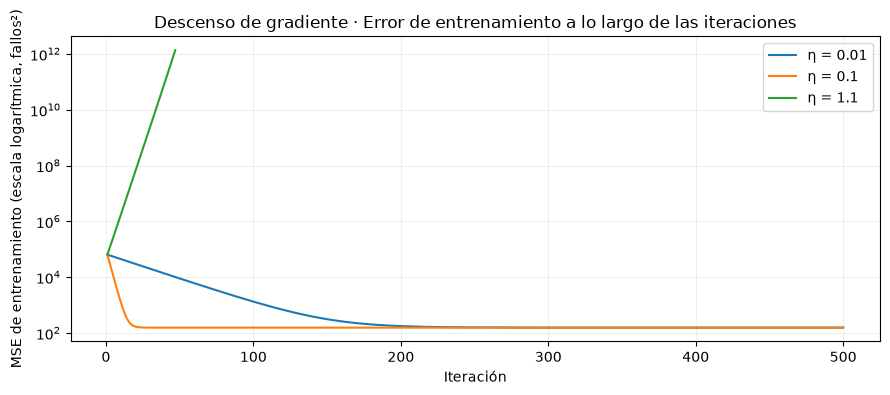

In [26]:
from sklearn.preprocessing import StandardScaler

# Se calcula la media y desviación de las DOS columnas usando solo días de entrenamiento.
escalador_gradiente = StandardScaler()
X_vpn_train_std = escalador_gradiente.fit_transform(X_vpn_train)

def ajustar_vpn_gradiente(X_estandar, y_real, eta, iteraciones=500):
    """Mínimos cuadrados con gradiente; devuelve pesos, intercepto, pérdidas e incidencia."""
    pesos = np.zeros(X_estandar.shape[1])  # Un peso por característica, todos a cero.
    base = 0.0                             # Intercepto inicial.
    historial_mse = []
    estado = "500 iteraciones completadas"
    for paso in range(iteraciones):
        diferencias = X_estandar @ pesos + base - y_real  # Predicho menos observado.
        mse = np.mean(diferencias ** 2)
        historial_mse.append(mse)
        if not np.isfinite(mse) or mse > 1e12:
            estado = f"divergencia detectada en iteración {paso + 1}"
            break
        # Exactamente la regla de actualización propuesta en el ejercicio.
        pesos -= eta * 2 * X_estandar.T @ diferencias / len(y_real)
        base -= eta * 2 * diferencias.mean()
    return pesos, base, historial_mse, estado

resultados_gradiente = []
historiales_gradiente = {}
for tasa in [0.01, 0.1, 1.1]:
    pesos, base, perdidas, estado = ajustar_vpn_gradiente(X_vpn_train_std, y_vpn_train, tasa)
    historiales_gradiente[tasa] = perdidas
    resultados_gradiente.append({
        "η (tasa de aprendizaje)": tasa,
        "Iteraciones realizadas": len(perdidas),
        "MSE inicial (fallos²)": perdidas[0],
        "MSE final (fallos²)": perdidas[-1],
        "Estado": estado,
    })

print("=" * 74)
print("A.3 · RETO · Velocidad y estabilidad del descenso de gradiente")
print("=" * 74)
display(pd.DataFrame(resultados_gradiente).round(3).set_index("η (tasa de aprendizaje)"))

fig, ax = plt.subplots(figsize=(9, 4))
for tasa, perdidas in historiales_gradiente.items():
    ax.plot(np.arange(1, len(perdidas) + 1), perdidas, label=f"η = {tasa}")
ax.set(title="Descenso de gradiente · Error de entrenamiento a lo largo de las iteraciones",
       xlabel="Iteración", ylabel="MSE de entrenamiento (escala logarítmica, fallos²)",
       yscale="log")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Respuesta a la primera mitad del reto:** el gráfico muestra **cuántos pasos tarda en disminuir el MSE** cada tasa; una curva que se dispara en escala logarítmica indica inestabilidad. Con los datos y la estandarización fijados aquí, `η=0,01` debería avanzar de forma gradual, `η=0,1` más rápidamente y `η=1,1` ser demasiado grande. La tabla permite verificarlo sin fiarse de una afirmación genérica. El *MSE* tiene unidades de `(fallos/día)²`; por eso la gráfica usa escala logarítmica, que permite ver simultáneamente valores muy diferentes. No confundas un error de entrenamiento pequeño con garantía de éxito futuro: el día 100 ni siquiera aparece en los ejemplos usados para ajustar estos pesos.

**Segunda mitad del reto — Ridge:** una recta solo puede representar una combinación lineal de `día` y `finde`. `PolynomialFeatures(degree=15)` genera términos como `día²` o `día·finde`, capaces de ajustar curvas muy complejas. Con solo 90 días de entrenamiento, tanta flexibilidad puede **sobreajustar** el ruido. `Ridge` minimiza el error cuadrático **más** una penalización `α × suma(peso²)`: `α` grande reduce coeficientes grandes y suele suavizar el ajuste. Para que términos elevados (`día^15`) no dominen por su magnitud, escalamos **dentro** del pipeline antes de crear los polinomios. Ese escalado adicional favorece la estabilidad numérica, pero es una elección explícita de preprocesamiento, no una transformación presente en el código base.

In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

# Los errores de train y test se miden sobre EXACTAMENTE los mismos 90/30 días de A.1.
filas_ridge = [{
    "Modelo": "Regresión lineal (referencia)",
    "RMSE train (fallos/día)": mean_squared_error(y_vpn_train, modelo_vpn.predict(X_vpn_train)) ** 0.5,
    "RMSE test (fallos/día)": rmse_vpn,
}]
for alpha in [0.01, 1, 100]:
    # fit() del pipeline ajusta el escalador solamente a los primeros 90 días.
    modelo_ridge = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=15),  # Genera todas las combinaciones hasta grado 15.
        Ridge(alpha=alpha),             # Penaliza pesos muy grandes para reducir sobreajuste.
    )
    modelo_ridge.fit(X_vpn_train, y_vpn_train)
    filas_ridge.append({
        "Modelo": f"Polinomio grado 15 + Ridge α={alpha}",
        "RMSE train (fallos/día)": mean_squared_error(y_vpn_train, modelo_ridge.predict(X_vpn_train)) ** 0.5,
        "RMSE test (fallos/día)": mean_squared_error(y_vpn_test, modelo_ridge.predict(X_vpn_test)) ** 0.5,
    })

tabla_ridge = pd.DataFrame(filas_ridge)
print("=" * 74)
print("A.4 · RETO · Complejidad polinómica y regularización")
print("=" * 74)
display(tabla_ridge.round(2).set_index("Modelo"))

A.4 · RETO · Complejidad polinómica y regularización


,RMSE train (fallos/día),RMSE test (fallos/día)
Modelo,,
Regresión lineal (referencia),12.51,72.72
Polinomio grado 15 + Ridge α=0.01,11.01,2890730.79
Polinomio grado 15 + Ridge α=1,11.45,1408220.78
Polinomio grado 15 + Ridge α=100,16.50,481455.70


**Cómo responder al reto con la tabla:** compara cada par de columnas. Si un polinomio tiene **RMSE de entrenamiento muy bajo y RMSE de test elevado**, aprendió detalles que no generalizan (*sobreajuste*). Si ambos son altos, podría faltar capacidad o haber demasiado sesgo. Un `α` más grande cambia el equilibrio, pero **no garantiza** ser mejor: consulta los valores ejecutados. El día 100, introducido deliberadamente solo en prueba, empeora el RMSE de test incluso para un buen modelo de comportamiento normal. A diferencia de la parte C, aquí **no estamos seleccionando un umbral de alerta en test**: estamos comparando ajustes dentro de un ejercicio ilustrativo.

---
## Parte B · Regresión logística desde cero: de características a probabilidades

**Problema:** una regresión lineal predice una cantidad que puede ser cualquier número; al detectar ataques nos interesan dos clases (`0 = normal`, `1 = ataque`) y una puntuación entre `0` y `1` que podamos interpretar como **probabilidad estimada de ataque**.

Usaremos **dos características de NSL-KDD** por conexión: `serror_rate` (proporción de conexiones con errores de tipo SYN, según la definición del conjunto) y `same_srv_rate` (proporción de conexiones dirigidas al mismo servicio en una ventana contextual). Ambas son **variables de entrada**, no la verdad de ataque. Se estandarizan restando su media de entrenamiento y dividiendo por su desviación; a partir de ellas obtenemos `z = w₁·x₁ + w₂·x₂ + b`. Una función **sigmoide** convierte ese número en una salida entre 0 y 1:

\[
P(ataque\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}.
\]

Si `z = 0`, entonces `P = 0,5`; si `z ≈ 2,2`, `P ≈ 0,90`; si `z ≈ −2,2`, `P ≈ 0,10`. El modelo **no** descubre esa probabilidad por contar ataques a ojo: aprende `w` y `b` ajustando sus predicciones a ejemplos etiquetados.

**¿Qué optimizamos?** El *log-loss* penaliza que un modelo asigne una probabilidad baja a la clase que efectivamente ocurrió:

\[
L=-\frac{1}{n}\sum_i\big[y_i\ln(p_i)+(1-y_i)\ln(1-p_i)\big].
\]

Para `y=1`, predecir `p=0,99` cuesta aproximadamente `0,01`, mientras `p=0,01` cuesta `4,61`. El descenso de gradiente cambia los parámetros para disminuir esta pérdida. `η=0,5` es la tasa de aprendizaje y `epochs=400` son **400 recorridos de ajuste**, no 400 filas.

B.1 · LOGÍSTICA · Comparación de dos formas de entrenar
Conexiones utilizadas para aprender: 125,973 · Características: 2


,Desde cero,scikit-learn
Parámetro,,
Peso de serror_rate,1.263,1.276
Peso de same_srv_rate,-1.718,-1.717
Intercepto (b),0.471,0.479


Log-loss inicial: 0.6931 · Log-loss final: 0.3357


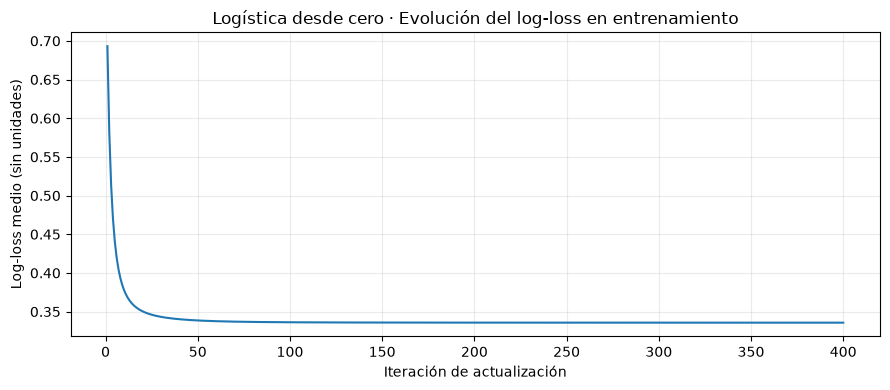

In [28]:
from sklearn.linear_model import LogisticRegression

# Elegimos únicamente dos columnas para poder representar la frontera en un plano.
atributos_logistica = ["serror_rate", "same_srv_rate"]
media_logistica = tr[atributos_logistica].mean()
desviacion_logistica = tr[atributos_logistica].std()

# Restar la media y dividir por la desviación típica hace comparables las escalas.
X_logistica = ((tr[atributos_logistica] - media_logistica) / desviacion_logistica).to_numpy()
y_logistica = tr["is_attack"].to_numpy()  # 0 = normal; 1 = ataque.

def sigmoid(z):
    """Transforma una puntuación real z en una probabilidad entre cero y uno."""
    return 1 / (1 + np.exp(-z))

def entrenar_logistica_desde_cero(X, y, eta=0.5, epochs=400):
    """Desciende la pérdida logarítmica con gradiente; recibe [filas, atributos]."""
    pesos = np.zeros(X.shape[1])
    base = 0.0
    historial_loss = []
    for epoca in range(epochs):
        prob_ataque = sigmoid(X @ pesos + base)  # Una probabilidad por conexión.
        error = prob_ataque - y                 # Diferencia respecto a etiqueta real.
        # Promediar por n hace que el tamaño del paso no crezca al añadir filas.
        pesos -= eta * X.T @ error / len(y)
        base -= eta * error.mean()
        # +1e-12 evita calcular log(0) por redondeo; no cambia las etiquetas.
        loss = -np.mean(
            y * np.log(prob_ataque + 1e-12)
            + (1 - y) * np.log(1 - prob_ataque + 1e-12)
        )
        historial_loss.append(loss)
    return pesos, base, historial_loss

pesos_logistica, base_logistica, historial_logistica = entrenar_logistica_desde_cero(
    X_logistica, y_logistica
)
# C=1e6 equivale a regularización casi nula, para comparar con nuestro código.
modelo_logistica_sklearn = LogisticRegression(C=1e6).fit(X_logistica, y_logistica)

comparacion_logistica = pd.DataFrame({
    "Parámetro": ["Peso de serror_rate", "Peso de same_srv_rate", "Intercepto (b)"],
    "Desde cero": [*pesos_logistica, base_logistica],
    "scikit-learn": [*modelo_logistica_sklearn.coef_[0], modelo_logistica_sklearn.intercept_[0]],
})
print("=" * 74)
print("B.1 · LOGÍSTICA · Comparación de dos formas de entrenar")
print("=" * 74)
print(f"Conexiones utilizadas para aprender: {len(y_logistica):,} · Características: {len(atributos_logistica)}")
display(comparacion_logistica.round(3).set_index("Parámetro"))
print(f"Log-loss inicial: {historial_logistica[0]:.4f} · Log-loss final: {historial_logistica[-1]:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(historial_logistica) + 1), historial_logistica)
ax.set(title="Logística desde cero · Evolución del log-loss en entrenamiento",
       xlabel="Iteración de actualización", ylabel="Log-loss medio (sin unidades)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Cómo interpretar B.1:** los valores de `Desde cero` y `scikit-learn` deben ser **parecidos**, no necesariamente idénticos: la optimización usa métodos, tolerancias y criterios de parada diferentes. Cada peso se interpreta **manteniendo la otra característica constante**: un peso positivo hace crecer la puntuación `z` y por tanto la probabilidad estimada de ataque; uno negativo la reduce. Como las entradas están estandarizadas, un incremento de `1` representa aproximadamente **una desviación típica**, no una unidad natural de tráfico. El intercepto `b` es la puntuación cuando ambas características igualan su media de entrenamiento.

Si la curva del log-loss baja y se estabiliza, el algoritmo está aprendiendo una solución para **esas dos columnas de entrenamiento**; no demuestra por sí sola que haya buena generalización en `te`. Además, la pérdida registrada aquí corresponde a las probabilidades **calculadas antes de cada actualización**, tal como hacía el código original: el último punto describe el estado justo antes de aplicar el último paso.

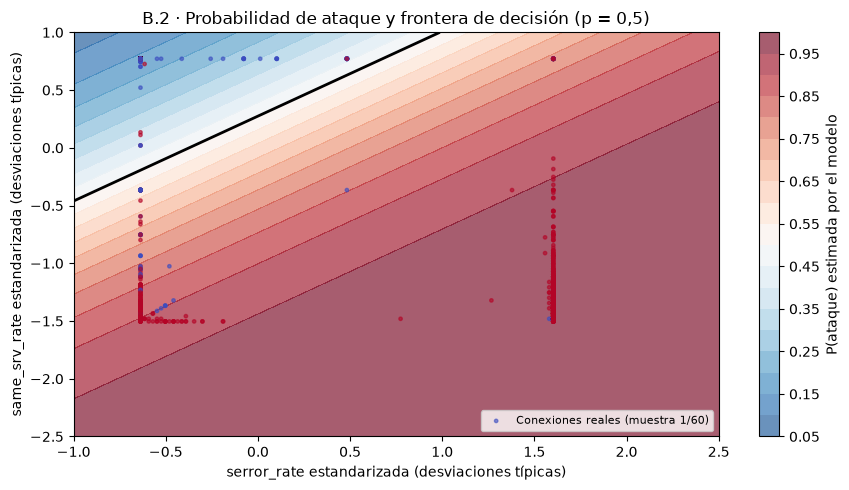

In [29]:
# Crear un plano de valores posibles para las dos características ESTANDARIZADAS.
rejilla_error, rejilla_servicio = np.meshgrid(
    np.linspace(-1, 2.5, 200),
    np.linspace(-2.5, 1, 200),
)
entradas_rejilla = np.c_[rejilla_error.ravel(), rejilla_servicio.ravel()]
probabilidades_rejilla = sigmoid(
    entradas_rejilla @ pesos_logistica + base_logistica
).reshape(rejilla_error.shape)

fig, ax = plt.subplots(figsize=(9, 5))
colores = ax.contourf(rejilla_error, rejilla_servicio, probabilidades_rejilla,
                     levels=20, alpha=0.65, cmap="RdBu_r", vmin=0, vmax=1)
fig.colorbar(colores, ax=ax, label="P(ataque) estimada por el modelo")
# La línea negra indica probabilidad 0.5: el lugar donde cambia la clase predicha.
ax.contour(rejilla_error, rejilla_servicio, probabilidades_rejilla,
           levels=[0.5], colors="black", linewidths=2)
ax.scatter(X_logistica[::60, 0], X_logistica[::60, 1],
           c=y_logistica[::60], s=6, cmap="coolwarm", vmin=0, vmax=1,
           alpha=0.6, label="Conexiones reales (muestra 1/60)")
ax.set(xlabel="serror_rate estandarizada (desviaciones típicas)",
       ylabel="same_srv_rate estandarizada (desviaciones típicas)",
       title="B.2 · Probabilidad de ataque y frontera de decisión (p = 0,5)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**Cómo leer el gráfico:** el fondo coloreado es la **probabilidad estimada** sobre distintas parejas de características; cada punto pequeño es una conexión real (solo se dibuja 1 de cada 60 para evitar saturación). La línea negra cumple `P(ataque)=0,5`, equivalente a `w₁·x₁+w₂·x₂+b=0`: es una **recta** en este plano. Las zonas coloreadas no prueban qué conexiones eran ataques: la etiqueta verdadera está en los datos, no en el fondo. Observa si aparecen puntos de ambas clases en una misma zona; eso ilustra la limitación de intentar clasificar usando solo dos características. La sigmoide curvada **no** vuelve curva la frontera `P=0,5` mientras la puntuación `z` sea una combinación lineal de las entradas.

### Reto avanzado B · Tasa de aprendizaje y criterio de entrenamiento (resuelto)

**Enunciado original:** repetir con `η=0,01` y `η=20`, explicar convergencia frente a oscilación/divergencia, por qué vigilar *log-loss* además de exactitud y por qué la frontera de decisión es una recta.

Conservaremos **las mismas dos entradas de NSL-KDD**, **400 iteraciones** y la misma función de pérdida, cambiando solo el tamaño de paso. La *exactitud* (`accuracy`) es `aciertos / total`: necesita convertir probabilidades en etiquetas con umbral `0,5`. Dos modelos pueden acertar las mismas filas y tener probabilidades muy distintas. Por ejemplo, ante un ataque real, `0,51` y `0,99` son ambos aciertos, pero sus pérdidas son `−ln(0,51)≈0,673` y `−ln(0,99)≈0,010`: el log-loss también evalúa **cuán acertada es la confianza** del modelo, no solo el lado del umbral.

B.3 · RETO · Mismo modelo, diferente tasa de aprendizaje


,Log-loss inicial,Log-loss último registro,Exactitud en train
η,,,
0.01,0.6931,0.3906,0.8741
0.50,0.6931,0.3357,0.8693
20.00,0.6931,0.4582,0.8753


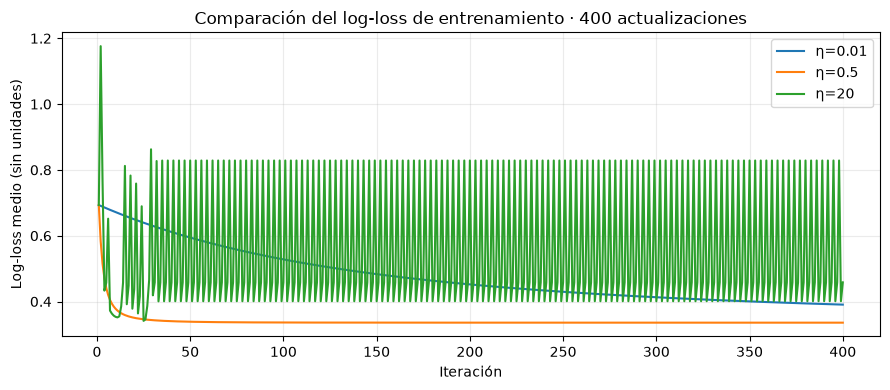

In [30]:
from sklearn.metrics import accuracy_score

historiales_tasas = {}
resumen_tasas = []
for tasa in [0.01, 0.5, 20]:
    pesos_tasa, base_tasa, perdidas_tasa = entrenar_logistica_desde_cero(
        X_logistica, y_logistica, eta=tasa, epochs=400
    )
    historiales_tasas[tasa] = perdidas_tasa
    prob_final = sigmoid(X_logistica @ pesos_tasa + base_tasa)
    clasificaciones = (prob_final > 0.5).astype(int)
    resumen_tasas.append({
        "η": tasa,
        "Log-loss inicial": perdidas_tasa[0],
        "Log-loss último registro": perdidas_tasa[-1],
        "Exactitud en train": accuracy_score(y_logistica, clasificaciones),
    })

print("=" * 74)
print("B.3 · RETO · Mismo modelo, diferente tasa de aprendizaje")
print("=" * 74)
display(pd.DataFrame(resumen_tasas).round(4).set_index("η"))
fig, ax = plt.subplots(figsize=(9, 4))
for tasa, perdidas in historiales_tasas.items():
    ax.plot(np.arange(1, len(perdidas) + 1), perdidas, label=f"η={tasa}")
ax.set(title="Comparación del log-loss de entrenamiento · 400 actualizaciones",
       xlabel="Iteración", ylabel="Log-loss medio (sin unidades)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Respuesta al reto B:** compara **curvas completas**, no solo la última cifra. Con `η` pequeño se avanza lentamente; si la pérdida cae rápidamente y permanece estable, el paso permite converger. Con un `η` excesivo se puede **oscilar, empeorar o saturarse**: no es correcto asegurar que `η=20` siempre diverge sin mirar la ejecución y el dataset. Tampoco confundas una exactitud similar con pérdidas iguales: un modelo puede pasar de probabilidades prudentes a probabilidades extremas sin cambiar muchas clases predichas. Y la frontera sigue siendo una recta porque decidir `P>0,5` equivale a decidir `z>0`, donde `z=w₁x₁+w₂x₂+b`. En espacios con más características es un **hiperplano**, generalización de una recta.

---
## Parte C · Regresión logística con NSL-KDD completo: *odds* y costes de alerta

**Problema:** dos características eran cómodas para dibujar, pero un detector serio necesita más información. Entrenaremos otra regresión logística con **15 características numéricas** (`duration`, `src_bytes`, tasas de error, etc.) y **2 categóricas** (`protocol_type` y `flag`). El resultado seguirá siendo la probabilidad estimada de `is_attack=1`.

**Preparación de entrada:**

1. **Variables numéricas:** `log1p(x)=ln(1+x)` comprime valores grandes como bytes sin eliminar el cero (`log1p(0)=0`). Ejemplo: `0`, `9` y `999` se transforman aproximadamente en `0`, `2,30` y `6,91`; después `StandardScaler` resta la media y divide por la desviación aprendidas **solo en train**. Se evita que diferencias gigantes en bytes dominen el entrenamiento.
2. **Variables categóricas:** un protocolo como `tcp` no es un número ordenable. `OneHotEncoder` crea columnas indicadoras (`tcp=1`, `udp=0`, …). Con `handle_unknown="ignore"`, una categoría solo vista en test no provoca un error: se representa con ceros en las columnas aprendidas.
3. **`ColumnTransformer`:** aplica ambos procedimientos a columnas distintas y reúne las salidas. **`make_pipeline(...)` une preparación y modelo**, de manera que las medias, categorías y coeficientes aprendidos en train se reutilizan sin recalcularlos en test.

La regresión logística con regularización L2 (`C=1.0`) tiende a evitar coeficientes excesivos; `C` es **inverso** de la fuerza de regularización (menor `C` → mayor penalización). `max_iter=2000` es un límite de iteraciones del optimizador, no el número de conexiones.

C.1 · MODELO BINARIO · Variables asociadas con normalidad y ataque
Conexiones de entrenamiento: 125,973 · Entradas originales: 17
Columnas resultantes tras el preprocesamiento: 29
Coeficientes más negativos y más positivos (log-odds por unidad transformada):


,Coeficiente (log-odds)
c__flag_S2,-4.325
c__flag_S1,-3.899
c__flag_REJ,-3.876
c__flag_RSTO,-3.327
c__protocol_type_tcp,-1.761
c__flag_S0,2.295
n__rerror_rate,2.396
c__flag_SH,3.079
c__flag_OTH,3.929
c__flag_RSTR,3.991


Odds ratio para n__serror_rate: exp(1.919) = 6.812


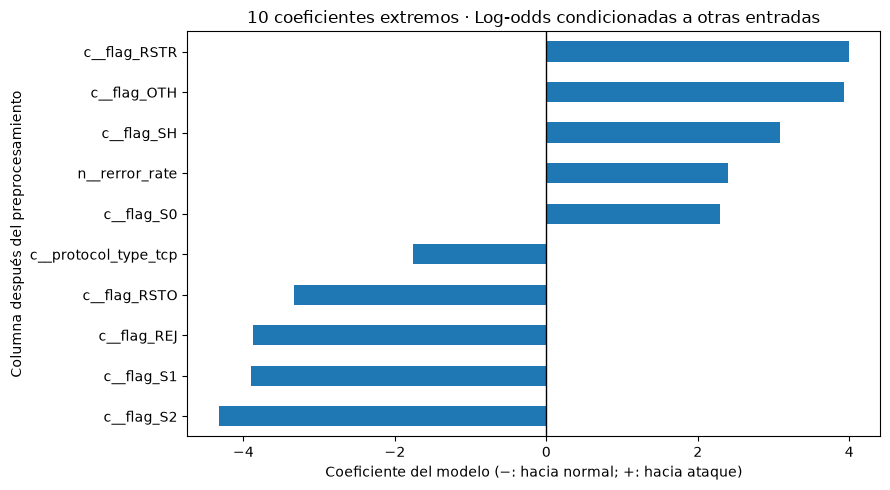

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, confusion_matrix

# Conservamos exactamente la selección original de 15 atributos numéricos y 2 categóricos.
atributos_numericos = [
    "duration", "src_bytes", "dst_bytes", "count", "srv_count",
    "serror_rate", "rerror_rate", "same_srv_rate", "diff_srv_rate",
    "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
    "logged_in", "hot", "num_failed_logins",
]
atributos_categoricos = ["protocol_type", "flag"]
atributos_nsl = atributos_numericos + atributos_categoricos

preparacion_nsl = ColumnTransformer([
    ("n", make_pipeline(
        FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
        StandardScaler(),
    ), atributos_numericos),
    ("c", OneHotEncoder(handle_unknown="ignore"), atributos_categoricos),
])

# La preparación forma parte del entrenamiento y se reaplica igual en predict().
modelo_nsl = make_pipeline(
    preparacion_nsl,
    LogisticRegression(C=1.0, max_iter=2000),
).fit(tr[atributos_nsl], tr["is_attack"])

# Cada columna transformada tiene su coeficiente; también los indicadores one-hot.
coeficientes_nsl = pd.Series(
    modelo_nsl[-1].coef_[0],
    index=modelo_nsl[0].get_feature_names_out(),
).sort_values()
coeficientes_destacados = pd.concat([
    coeficientes_nsl.head(5), coeficientes_nsl.tail(5),
])

# Odds ratio para una unidad de serror_rate YA transformada y estandarizada.
coef_error_sin = coeficientes_nsl["n__serror_rate"]
odds_ratio_serror = np.exp(coef_error_sin)

print("=" * 74)
print("C.1 · MODELO BINARIO · Variables asociadas con normalidad y ataque")
print("=" * 74)
print(f"Conexiones de entrenamiento: {len(tr):,} · Entradas originales: {len(atributos_nsl)}")
print(f"Columnas resultantes tras el preprocesamiento: {len(coeficientes_nsl)}")
print("Coeficientes más negativos y más positivos (log-odds por unidad transformada):")
display(coeficientes_destacados.rename("Coeficiente (log-odds)").round(3).to_frame())
print(f"Odds ratio para n__serror_rate: exp({coef_error_sin:.3f}) = {odds_ratio_serror:.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
coeficientes_destacados.plot.barh(ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set(title="10 coeficientes extremos · Log-odds condicionadas a otras entradas",
       xlabel="Coeficiente del modelo (−: hacia normal; +: hacia ataque)",
       ylabel="Columna después del preprocesamiento")
plt.tight_layout()
plt.show()

### C.1 · Interpretar bien un coeficiente y un *odds ratio*

La regresión logística no suma probabilidades: suma **logaritmos de odds**. Si una probabilidad es `p`, las **odds** son `p/(1−p)`, es decir, la proporción «ataque frente a no ataque». Con `p=0,2`, las odds son `0,2/0,8=0,25` (aprox. **1 frente a 4**). Un coeficiente `w` implica que, al aumentar **una unidad en la columna transformada** y mantener las demás constantes, esas odds se multiplican por `exp(w)`. Si `w=ln(2)≈0,693`, pasan de `0,25` a `0,50`, lo que corresponde a `p≈0,333`: **las odds se duplican, la probabilidad no**.

En esta sesión, `n__serror_rate` representa la tasa de error **después de `log1p` y de estandarizarla**. Por tanto, su `odds ratio` expresa un aumento de **una desviación típica de la variable log-transformada**, no «sumar una unidad a la tasa original». Las columnas `c__...` son indicadores de categorías. Un coeficiente positivo indica asociación con ataque **en presencia de las otras características**, no causalidad ni una regla universal. Como las características se relacionan entre sí y hay regularización, **un coeficiente extremo no equivale a la importancia causal de esa característica**.

### C.2 · Elegir un umbral de alerta según el coste de equivocarse

`predict_proba` devuelve por cada conexión dos probabilidades estimadas, una para `0=normal` y otra para `1=ataque`; `[ :, 1]` selecciona la **segunda columna**, la del ataque. Para convertirla en una alerta necesitamos un **umbral**: con `t=0,5` se clasifica como ataque si `P(ataque)>0,5`, pero el valor 0,5 no es obligatorio.

Una **matriz de confusión** para las clases `0=normal` y `1=ataque` distingue cuatro casos:

| | Predicción normal (0) | Predicción ataque (1) |
|:--|:--|:--|
| **Real normal (0)** | **TN**, correcto sin alerta | **FP**, falsa alarma |
| **Real ataque (1)** | **FN**, ataque omitido | **TP**, ataque detectado |

**Recall de ataques** = `TP/(TP+FN)` → ¿qué proporción de ataques detecta? **Precisión de las alertas** = `TP/(TP+FP)` → ¿qué proporción de alertas se refiere a ataques reales? Ejemplo: si hay `100` ataques y encontramos `90`, el recall es `90 %`; si además dimos `30` falsas alarmas, la precisión es `90/(90+30)=75 %`. Ambas métricas responden preguntas distintas.

El ejercicio supone **coste(FN)=50** y **coste(FP)=1**, en unidades de coste inventadas y relativas; ignora otros costes para aislar la decisión: `coste total = 50×FN+FP`. Revisaremos seis umbrales `[0,05; 0,1; 0,3; 0,5; 0,7; 0,9]`. **Advertencia metodológica:** la celda original busca el menor coste **en test**. Conservamos ese cálculo como demostración, pero **no** es una evaluación final válida para seleccionar el umbral; el reto siguiente lo elige en validación.

In [32]:
# Un valor por conexión de PRUEBA: probabilidad estimada de la clase 1=ataque.
probabilidades_nsl_test = modelo_nsl.predict_proba(te[atributos_nsl])[:, 1]
umbrales_candidatos = [0.05, 0.1, 0.3, 0.5, 0.7, 0.9]
filas_coste_test = []

for umbral in umbrales_candidatos:
    # El > reproduce el criterio original; un valor exactamente igual no genera alerta.
    prediccion_umbral = (probabilidades_nsl_test > umbral).astype(int)
    # En clasificación binaria: flatten = [TN, FP, FN, TP].
    tn, fp, fn, tp = confusion_matrix(te["is_attack"], prediccion_umbral,
                                      labels=[0, 1]).ravel()
    filas_coste_test.append({
        "Umbral P(ataque)": umbral,
        "Recall ataques": tp / (tp + fn) if tp + fn else np.nan,
        "Precisión alertas": tp / (tp + fp) if tp + fp else np.nan,
        "FN (ataques omitidos)": fn,
        "FP (falsas alarmas)": fp,
        "Coste = 50×FN + FP": 50 * fn + fp,
    })

tabla_costes_test = pd.DataFrame(filas_coste_test)
indice_menor_coste_test = tabla_costes_test["Coste = 50×FN + FP"].idxmin()
umbral_mejor_test_solo_demo = tabla_costes_test.loc[indice_menor_coste_test, "Umbral P(ataque)"]

print("=" * 80)
print("C.2 · DEMOSTRACIÓN CON TEST · Coste hipotético de falsos negativos y positivos")
print("=" * 80)
print("Costes supuestos: FN = 50 unidades · FP = 1 unidad; no son costes de un SOC real.")
display(tabla_costes_test.round(3).set_index("Umbral P(ataque)"))
print(f"Menor coste dentro de los seis umbrales, medido EN TEST: {umbral_mejor_test_solo_demo:.2f}")
print("AVISO: es una comparación didáctica; no reutilices el test para seleccionar un umbral final.")

C.2 · DEMOSTRACIÓN CON TEST · Coste hipotético de falsos negativos y positivos
Costes supuestos: FN = 50 unidades · FP = 1 unidad; no son costes de un SOC real.


,Recall ataques,Precisión alertas,FN (ataques omitidos),FP (falsas alarmas),Coste = 50×FN + FP
Umbral P(ataque),,,,,
0.05,0.700,0.846,3852,1632,194232
0.10,0.679,0.876,4114,1232,206932
0.30,0.628,0.954,4771,392,238942
0.50,0.605,0.965,5067,278,253628
0.70,0.591,0.978,5255,171,262921
0.90,0.517,0.991,6195,59,309809


Menor coste dentro de los seis umbrales, medido EN TEST: 0.05
AVISO: es una comparación didáctica; no reutilices el test para seleccionar un umbral final.


**Cómo extraer una conclusión sin engañarse:** al reducir el umbral, normalmente aumenta el *recall* porque se alertan más conexiones; también pueden subir los **FP**, que saturan al analista. Como cada **FN** cuesta aquí 50 veces un **FP**, se favorecen umbrales sensibles al ataque. El valor «mejor» **solo es el más barato de los seis probados**, según el coste inventado y el test consultado; no es necesariamente el óptimo global ni tiene por qué estar siempre por debajo de 0,5 en otros datasets o modelos. La cifra de precisión es **indefinida** si no se produjo ninguna alerta: en ese caso mostramos `NaN` y no la interpretamos como cero.

**¿Es 0,5 el umbral óptimo para un SOC?** No podemos asumirlo. Depende de cuánto cuesten los ataques omitidos, la investigación de alertas, la proporción de ataques y la calibración del modelo. Un SOC debe elegir umbrales y políticas en **validación**, contrastarlos con un periodo no usado para ajustar decisiones y supervisar los cambios en tráfico real.

### Reto avanzado C · `class_weight="balanced"` y elección del umbral sin consultar test

**Enunciado original:** repetir con pesos de clase equilibrados, comparar umbrales y elegir el umbral usando validación separada antes de aplicarlo una sola vez al test.

`class_weight="balanced"` da **más peso en la función de entrenamiento** a los ejemplos de una clase poco frecuente, de manera inversamente proporcional a su frecuencia. No inventa datos adicionales ni fija por sí solo el umbral óptimo. Puede aumentar la detección de ataques y también las falsas alarmas; además puede alterar la interpretación de `predict_proba` como probabilidad calibrada.

Dividiremos **únicamente `tr`** en `80 %` para ajustar y `20 %` para validar (`stratify` mantiene aproximadamente la proporción de ataques). Ajustaremos dos modelos **sobre el mismo subconjunto de entrenamiento**: el original y otro con clases equilibradas. Para cada uno mediremos el coste de los seis umbrales **en validación**. Elegiremos el par `(modelo, umbral)` de **menor coste de validación** y solo entonces evaluaremos **ese par ganador** sobre `te`. Así las etiquetas de prueba no influyen en esa elección. Nota importante: en un ejercicio real «a ciegas» se habría evitado también mirar los resultados de test de C.2 antes de diseñar esta comparación.

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

# tr es el conjunto de entrenamiento OFICIAL; lo partimos internamente para validar.
filas_ajuste, filas_validacion = train_test_split(
    tr, test_size=0.20, stratify=tr["is_attack"], random_state=0
)

# clone() crea un preprocesador independiente; evita reutilizar escaladores ya ajustados.
modelos_validacion = {
    "Sin ponderar": make_pipeline(
        clone(preparacion_nsl), LogisticRegression(C=1.0, max_iter=2000)
    ),
    "Clases equilibradas": make_pipeline(
        clone(preparacion_nsl), LogisticRegression(C=1.0, max_iter=2000,
                                                  class_weight="balanced")
    ),
}

resultados_validacion = []
for nombre_modelo, modelo in modelos_validacion.items():
    modelo.fit(filas_ajuste[atributos_nsl], filas_ajuste["is_attack"])
    probabilidades_validacion = modelo.predict_proba(filas_validacion[atributos_nsl])[:, 1]
    for umbral in umbrales_candidatos:
        pred_validacion = (probabilidades_validacion > umbral).astype(int)
        tn, fp, fn, tp = confusion_matrix(filas_validacion["is_attack"],
                                          pred_validacion, labels=[0, 1]).ravel()
        resultados_validacion.append({
            "Modelo": nombre_modelo,
            "Umbral": umbral,
            "FN validación": fn,
            "FP validación": fp,
            "Recall validación": tp / (tp + fn) if tp + fn else np.nan,
            "Precisión validación": tp / (tp + fp) if tp + fp else np.nan,
            "Coste validación = 50×FN + FP": 50 * fn + fp,
        })

tabla_validacion = pd.DataFrame(resultados_validacion)
ganador_validacion = tabla_validacion.loc[
    tabla_validacion["Coste validación = 50×FN + FP"].idxmin()
]
nombre_ganador = ganador_validacion["Modelo"]
umbral_elegido = float(ganador_validacion["Umbral"])

print("=" * 82)
print("C.3 · RETO · Selección de modelo y umbral SOLO con validación")
print("=" * 82)
print(f"Conexiones de ajuste: {len(filas_ajuste):,} · Validación: {len(filas_validacion):,}")
display(tabla_validacion.round(3).set_index(["Modelo", "Umbral"]))
print(f"Ganador según VALIDACIÓN: {nombre_ganador}, umbral {umbral_elegido:.2f}")
print(f"Coste observado en validación: {int(ganador_validacion['Coste validación = 50×FN + FP'])} unidades hipotéticas")

# Evaluar SOLO el ganador, sin volver a ajustar parámetros ni umbral con el test.
modelo_ganador = modelos_validacion[nombre_ganador]
probabilidades_ganador_test = modelo_ganador.predict_proba(te[atributos_nsl])[:, 1]
pred_ganador_test = (probabilidades_ganador_test > umbral_elegido).astype(int)
tn_g, fp_g, fn_g, tp_g = confusion_matrix(te["is_attack"], pred_ganador_test,
                                          labels=[0, 1]).ravel()

print("\nRESULTADO FINAL DEL RETO · Una sola evaluación del modelo ganador en test")
print(f"  TN, FP, FN, TP : {tn_g:,}, {fp_g:,}, {fn_g:,}, {tp_g:,} conexiones")
print(f"  Recall ataques: {tp_g / (tp_g + fn_g):.3f}")
print(f"  Precisión alertas: {tp_g / (tp_g + fp_g):.3f}" if tp_g + fp_g else "  Precisión alertas: no definida (sin alertas)")
print(f"  Coste de test: {50 * fn_g + fp_g:,} unidades hipotéticas")

C.3 · RETO · Selección de modelo y umbral SOLO con validación
Conexiones de ajuste: 100,778 · Validación: 25,195


FN validación  FP validación  Recall validación  \
Modelo              Umbral                                                    
Sin ponderar        0.05              176           3566              0.985   
                    0.10              233           2365              0.980   
                    0.30              375            870              0.968   
                    0.50              739            482              0.937   
                    0.70              978            282              0.917   
                    0.90             1818            138              0.845   
Clases equilibradas 0.05              143           3693              0.988   
                    0.10              212           2634              0.982   
                    0.30              355            937              0.970   
                    0.50              707            535              0.940   
                    0.70              928            316              0.921   
                    0.90             1725            173              0.853   

                            Precisión validación  \
Modelo              Umbral                         
Sin ponderar        0.05                   0.764   
                    0.10                   0.829   
                    0.30                   0.929   
                    0.50                   0.958   
                    0.70                   0.974   
                    0.90                   0.986   
Clases equilibradas 0.05                   0.758   
                    0.10                   0.814   
                    0.30                   0.924   
                    0.50                   0.954   
                    0.70                   0.972   
                    0.90                   0.983   

                            Coste validación = 50×FN + FP  
Modelo              Umbral                                 
Sin ponderar        0.05                            12366  
                    0.10                            14015  
                    0.30                            19620  
                    0.50                            37432  
                    0.70                            49182  
                    0.90                            91038  
Clases equilibradas 0.05                            10843  
                    0.10                            13234  
                    0.30                            18687  
                    0.50                            35885  
                    0.70                            46716  
                    0.90                            86423

Ganador según VALIDACIÓN: Clases equilibradas, umbral 0.05
Coste observado en validación: 10843 unidades hipotéticas

RESULTADO FINAL DEL RETO · Una sola evaluación del modelo ganador en test
  TN, FP, FN, TP : 8,009, 1,702, 3,741, 9,092 conexiones
  Recall ataques: 0.708
  Precisión alertas: 0.842
  Coste de test: 188,752 unidades hipotéticas


**Respuesta al reto C:** la primera tabla permite separar dos efectos: los cambios producidos por el **peso de clase** y los producidos por el **umbral**. Una puntuación de coste menor en validación es una **observación de este experimento**, no una propiedad intrínseca de `balanced`. La evaluación final sobre test responde a «¿funciona el par ya elegido con datos distintos?». Si el coste crece respecto a validación, puede haber cambio de distribución, variación de muestra o sobreajuste de la selección; las cifras no bastan para decidir cuál es la causa. Hemos dejado el modelo ajustado con el 80 % de `tr` porque **reajustarlo con más datos cambiaría sus probabilidades** y entonces habría que verificar de nuevo la compatibilidad del umbral seleccionado.

---
## Parte D · Naive Bayes: un detector de phishing basado en palabras

**Problema:** ¿cómo convertir frases en números para estimar si un mensaje es sospechoso? Creamos un conjunto de **12 mensajes sintéticos**: 6 ejemplos etiquetados `1 = phishing` (fraude) y 6 como `0 = legítimo`. Las frases no corresponden a correos reales y el modelo **no puede utilizarse como filtro de correo fiable**. El material original señala una sesión posterior (la sesión 13) para un detector de phishing real; aquí basta entender el mecanismo.

**Primero, el texto se convierte en números.** `CountVectorizer` construye un **vocabulario** con las palabras del conjunto de entrenamiento (por defecto pasa a minúsculas y descarta tokens de un único carácter) y sustituye cada mensaje por un **vector de recuentos**. Por ejemplo, con vocabulario `["acta", "urgente"]`, «acta urgente urgente» se transforma en `[1, 2]`. La matriz resultante tiene **filas = mensajes** y **columnas = palabras**; es *dispersa* porque cada correo usa pocas palabras de todo el vocabulario. Importante: este vectorizador no entiende negaciones, intención ni sinónimos; generalmente tampoco conserva el orden de las palabras.

**Después, Naive Bayes multinomial** estima cuán frecuentes son esas palabras en cada clase y aplica el teorema de Bayes:

\[
P(clase\mid palabras) \propto P(clase)\,\prod_{palabra}P(palabra\mid clase)^{veces}.
\]

En palabras: «un mensaje será más probable en la clase cuyas palabras resultan más habituales, teniendo en cuenta la frecuencia previa de esa clase». Se llama *naive* porque asume que las apariciones de las palabras son **independientes dentro de cada clase**, una simplificación práctica pero irreal: «verificar cuenta» y «reunión de equipo» contienen relaciones que el modelo ignora.

`alpha=1.0` activa el **suavizado de Laplace**: se suma una aparición ficticia de cada palabra a cada clase. Sin él, una palabra nunca vista con cierta clase produciría probabilidad `0` y arruinaría el producto completo, aunque otras palabras favorecieran claramente esa clase.

In [34]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

# Dataset EXACTAMENTE como el original: seis mensajes de phishing y seis legítimos.
mensajes_entrenamiento = [
    "urgente verifique su cuenta bancaria ahora",
    "su paquete esta retenido pague la tasa",
    "has ganado un premio haz clic aqui",
    "su cuenta sera suspendida confirme su contrasena",
    "factura pendiente descargue el adjunto urgente",
    "alerta de seguridad inicie sesion ya",
    "reunion de equipo manana a las 10",
    "adjunto el informe trimestral para revision",
    "recordatorio de la formacion de ciberseguridad",
    "gracias por tu ayuda con el despliegue",
    "acta de la reunion del comite",
    "planificacion de vacaciones del departamento",
]
etiquetas_mensajes = [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0]

# fit_transform APRENDE vocabulario solo con entrenamiento y luego cuenta palabras.
vectorizador_mensajes = CountVectorizer()
X_mensajes = vectorizador_mensajes.fit_transform(mensajes_entrenamiento)
modelo_phishing_nb = MultinomialNB(alpha=1.0).fit(X_mensajes, etiquetas_mensajes)

# Mensajes nuevos: transform, no fit_transform, porque no queremos cambiar el vocabulario.
mensajes_nuevos = [
    "urgente confirme su cuenta",
    "adjunto el acta de la reunion",
    "pague ahora su factura",
]
X_mensajes_nuevos = vectorizador_mensajes.transform(mensajes_nuevos)
probabilidades_phishing = modelo_phishing_nb.predict_proba(X_mensajes_nuevos)[:, 1]

# Comparar probabilidades sin clasificar primero, para entender la incertidumbre del modelo.
tabla_mensajes = pd.DataFrame({
    "Mensaje nuevo": mensajes_nuevos,
    "P(phishing), según modelo": probabilidades_phishing,
    "Predicción con umbral 0,5": [
        "Phishing (1)" if p > 0.5 else "Legítimo (0)" for p in probabilidades_phishing
    ],
})

# En clase MultinomialNB guarda log(P(palabra|clase)); restar logaritmos compara clases.
vocabulario_phishing = np.array(vectorizador_mensajes.get_feature_names_out())
comparacion_palabras = (
    modelo_phishing_nb.feature_log_prob_[1] - modelo_phishing_nb.feature_log_prob_[0]
)
indices_top5 = np.argsort(comparacion_palabras)[-5:]

print("=" * 78)
print("D.1 · NAIVE BAYES · Mensajes de juguete, no un detector de producción")
print("=" * 78)
print(f"Mensajes de entrenamiento: {X_mensajes.shape[0]} (6 phishing; 6 legítimos)")
print(f"Palabras del vocabulario: {X_mensajes.shape[1]}")
print(f"Matriz de recuentos: {X_mensajes.shape[0]} mensajes × {X_mensajes.shape[1]} palabras")
display(tabla_mensajes)
print("Cinco palabras más asociadas con phishing, según la diferencia de log-probabilidad:")
display(pd.DataFrame({
    "Palabra": vocabulario_phishing[indices_top5],
    "Diferencia log P(palabra | phishing) − log P(palabra | legítimo)": comparacion_palabras[indices_top5],
}).sort_values(by="Diferencia log P(palabra | phishing) − log P(palabra | legítimo)",
               ascending=False).round(3).set_index("Palabra"))

D.1 · NAIVE BAYES · Mensajes de juguete, no un detector de producción
Mensajes de entrenamiento: 12 (6 phishing; 6 legítimos)
Palabras del vocabulario: 58
Matriz de recuentos: 12 mensajes × 58 palabras


,Mensaje nuevo,"P(phishing), según modelo","Predicción con umbral 0,5"
0,urgente confirme su cuenta,0.987558,Phishing (1)
1,adjunto el acta de la reunion,0.020040,Legítimo (0)
2,pague ahora su factura,0.972434,Phishing (1)


Cinco palabras más asociadas con phishing, según la diferencia de log-probabilidad:


,Diferencia log P(palabra | phishing) − log P(palabra | legítimo)
Palabra,
su,1.578
urgente,1.067
cuenta,1.067
tasa,0.662
verifique,0.662


**Cómo leer D.1:** la probabilidad es la salida **estimada por el modelo entrenado con solo 12 frases**, no la probabilidad comprobada de fraude del mensaje. Un valor `0,85` significa que el clasificador asigna `85 %` a la clase `1` **bajo sus hipótesis**, no que el correo tenga una garantía empírica del 85 % de ser malicioso. Las palabras más asociadas a phishing son las que reciben una probabilidad relativamente mayor en mensajes phishing **dentro de este pequeño dataset**, no un vocabulario universal de atacantes.

El código usa **`transform` para mensajes nuevos** porque el vocabulario debe permanecer fijo: si ejecutásemos `fit_transform` de nuevo, cambiaría el número u orden de columnas y el modelo dejaría de recibir las entradas con las que se entrenó. Si una palabra no aparecía en entrenamiento, **se ignora**, aunque sea importante para un analista humano. No existe aquí un test independiente suficiente para medir la fiabilidad de este clasificador.

### Reto avanzado D · Calcular Bayes a mano, entender `alpha` y engañar al modelo (resuelto)

**Enunciado original:** calcular `P(phishing | «urgente»)` a partir de las frecuencias, explicar el suavizado de Laplace y redactar **tres mensajes** que den lugar a predicciones erróneas.

Para reproducir **exactamente el `MultinomialNB(alpha=1)` usado**, no basta contar en cuántos mensajes aparece la palabra: se cuentan **apariciones de palabras**. Llamemos `V` al tamaño del vocabulario, `N_p` al número total de palabras en los 6 mensajes phishing y `N_l` al total en los 6 legítimos. Con `alpha=1`:

\[
P(urgente\mid phishing)=\frac{conteo_{phishing}(urgente)+1}{N_p+V},\quad
P(urgente\mid legítimo)=\frac{conteo_{legítimo}(urgente)+1}{N_l+V}.
\]

Como hay 6 ejemplos de cada clase, ambas probabilidades previas son `6/12 = 0,5`. Aplicamos Bayes usando **el documento de una sola palabra «urgente»**:

\[
P(phishing\mid urgente)=\frac{P(urgente\mid phishing)\,0,5}{P(urgente\mid phishing)\,0,5+P(urgente\mid legítimo)\,0,5}.
\]

Estos cálculos no son una frecuencia de documentos «que incluyen urgente», sino la probabilidad asignada por el **modelo multinomial suavizado**. La celda compara el resultado manual con `predict_proba`.

In [35]:
# Recuperar la columna numérica asociada exactamente a la palabra "urgente".
indice_urgente = vectorizador_mensajes.vocabulary_["urgente"]
matriz_conteos = X_mensajes.toarray()  # Aquí solo hay 12 filas; se puede densificar.
conteo_urgente_phishing = int(matriz_conteos[:6, indice_urgente].sum())
conteo_urgente_legitimo = int(matriz_conteos[6:, indice_urgente].sum())
tokens_phishing = int(matriz_conteos[:6].sum())
tokens_legitimos = int(matriz_conteos[6:].sum())
tamano_vocabulario = X_mensajes.shape[1]
alpha_nb = 1.0

# Probabilidad previa P(clase) = mensajes de esa clase / total de mensajes.
prior_phishing = sum(etiquetas_mensajes) / len(etiquetas_mensajes)
prior_legitimo = 1 - prior_phishing

# Cada palabra recibe alpha conteos ficticios dentro de CADA clase.
p_urgente_dado_phishing = (
    conteo_urgente_phishing + alpha_nb
) / (tokens_phishing + alpha_nb * tamano_vocabulario)
p_urgente_dado_legitimo = (
    conteo_urgente_legitimo + alpha_nb
) / (tokens_legitimos + alpha_nb * tamano_vocabulario)

numerador_bayes = p_urgente_dado_phishing * prior_phishing
posterior_manual = numerador_bayes / (
    numerador_bayes + p_urgente_dado_legitimo * prior_legitimo
)
posterior_sklearn = modelo_phishing_nb.predict_proba(
    vectorizador_mensajes.transform(["urgente"])
)[0, 1]

print("=" * 75)
print("D.2 · RETO · Teorema de Bayes para una sola palabra")
print("=" * 75)
print(f"Vocabulario total V: {tamano_vocabulario} palabras")
print(f"Apariciones 'urgente' en phishing: {conteo_urgente_phishing} de {tokens_phishing} tokens")
print(f"Apariciones 'urgente' en legítimos: {conteo_urgente_legitimo} de {tokens_legitimos} tokens")
print(f"P(urgente | phishing) = ({conteo_urgente_phishing} + 1) / "
      f"({tokens_phishing} + {tamano_vocabulario}) = {p_urgente_dado_phishing:.5f}")
print(f"P(urgente | legítimo) = ({conteo_urgente_legitimo} + 1) / "
      f"({tokens_legitimos} + {tamano_vocabulario}) = {p_urgente_dado_legitimo:.5f}")
print(f"P(phishing | 'urgente') calculada a mano: {posterior_manual:.5f}")
print(f"P(phishing | 'urgente') según scikit-learn: {posterior_sklearn:.5f}")
print(f"Coincidencia numérica: {np.isclose(posterior_manual, posterior_sklearn)}")

D.2 · RETO · Teorema de Bayes para una sola palabra
Vocabulario total V: 58 palabras
Apariciones 'urgente' en phishing: 2 de 39 tokens
Apariciones 'urgente' en legítimos: 0 de 36 tokens
P(urgente | phishing) = (2 + 1) / (39 + 58) = 0.03093
P(urgente | legítimo) = (0 + 1) / (36 + 58) = 0.01064
P(phishing | 'urgente') calculada a mano: 0.74406
P(phishing | 'urgente') según scikit-learn: 0.74406
Coincidencia numérica: True


**Respuesta a `alpha`:** con `alpha=0`, una palabra ausente en legítimos podría producir `P(palabra|legítimo)=0` y llevar todo el producto de probabilidades a cero para esa clase. Con `alpha=1`, cada una de las `V` palabras aporta `1` al numerador de su clase, por lo que el denominador crece en `V`. Así ninguna palabra conocida del vocabulario tiene probabilidad exactamente cero. El suavizado evita esa fragilidad, pero **no enseña semántica al modelo**. El valor calculado manualmente coincide con scikit-learn porque hemos utilizado sus **mismos recuentos y el mismo suavizado**; si contaras solo la proporción de mensajes que incluyen la palabra, obtendrías otra definición estadística y, por tanto, otra cifra.

In [36]:
# Tres errores intencionales: indicamos el contexto REAL que el modelo no conoce.
# Copiar frases de una clase en un mensaje de la otra ilustra su debilidad semántica.
mensajes_adversarios = [
    {"Mensaje": "urgente confirme su cuenta para la reunion", "Clase real": 0,
     "Contexto": "Mensaje legítimo: coordinación urgente de una reunión"},
    {"Mensaje": "alerta de seguridad urgente verifique su cuenta", "Clase real": 0,
     "Contexto": "Mensaje legítimo: aviso autorizado del equipo de seguridad"},
    {"Mensaje": "adjunto el informe trimestral para revision", "Clase real": 1,
     "Contexto": "Phishing: suplanta un mensaje normal e incluye un adjunto malicioso"},
]
textos_adversarios = [caso["Mensaje"] for caso in mensajes_adversarios]
prob_adversarias = modelo_phishing_nb.predict_proba(
    vectorizador_mensajes.transform(textos_adversarios)
)[:, 1]
resumen_adversarios = pd.DataFrame(mensajes_adversarios)
resumen_adversarios["P(phishing) del modelo"] = prob_adversarias
resumen_adversarios["Predicción (0/1)"] = (prob_adversarias > 0.5).astype(int)
resumen_adversarios["¿Se equivoca?"] = (
    resumen_adversarios["Predicción (0/1)"] != resumen_adversarios["Clase real"]
)

print("=" * 75)
print("D.3 · RETO · Tres mensajes que explotan las limitaciones del modelo")
print("=" * 75)
display(resumen_adversarios)
print(f"Errores en estos tres casos: {resumen_adversarios['¿Se equivoca?'].sum()} de 3.")

D.3 · RETO · Tres mensajes que explotan las limitaciones del modelo


,Mensaje,Clase real,Contexto,P(phishing) del modelo,Predicción (0/1),¿Se equivoca?
0,urgente confirme su cuenta para la reunion,0,Mensaje legítimo: coordinación urgente de una ...,0.889208,1,True
1,alerta de seguridad urgente verifique su cuenta,0,Mensaje legítimo: aviso autorizado del equipo ...,0.989724,1,True
2,adjunto el informe trimestral para revision,1,Phishing: suplanta un mensaje normal e incluye...,0.033357,0,True


Errores en estos tres casos: 3 de 3.


**Interpretación de D.3:** las «clases reales» son **supuestos explícitos del ejercicio**, incluidos el origen autorizado de los dos primeros mensajes y el adjunto malicioso del tercero. No se pueden averiguar esos hechos por el texto aislado. Si el modelo clasifica según expresiones que vio en una clase, puede confundir una advertencia legítima con phishing (**falso positivo**) o un señuelo bien redactado con correo legítimo (**falso negativo**). No son tres muestras independientes suficientes para calcular una tasa de error real; son **contraejemplos de su forma de razonar**. Para un detector real harían falta miles de ejemplos representativos, una separación de prueba estricta, contexto y mecanismos adicionales a las palabras.

---
## Parte E · k-NN y SVM: el efecto del escalado y el tamaño de los datos

**Problema:** comparar varios clasificadores sobre **15 características numéricas de NSL-KDD**. Elegimos aleatoriamente `12 000` conexiones **solo de `tr`** y las dividimos en `8 000` para ajuste y `4 000` para validación interna. `stratify=is_attack` conserva aproximadamente la proporción de clases y `random_state=0` permite repetir la selección. El conjunto oficial `te` **no se toca** durante esta comparación.

**k-NN (k vecinos más próximos):** al predecir una conexión nueva, busca sus `k=5` registros de entrenamiento más cercanos y decide por mayoría. Con la **distancia euclidiana** entre dos flujos, `d(a,b)=√Σ_j(a_j−b_j)²`, comparar bytes con tasas de error sin escalar puede ser engañoso: una diferencia de `100 000` bytes supera numéricamente una diferencia de `0,8` en una tasa. `StandardScaler` hace las unidades más comparables, pero no garantiza mejorar la clasificación si las escalas originales contenían una señal útil. `log1p` puede ayudar cuando existen **colas largas**, es decir, unos pocos flujos con bytes muchísimo mayores que la mayoría.

**SVM lineal:** aprende una frontera que intenta separar las clases con un **margen** amplio; su ecuación de decisión es lineal en las características transformadas. **SVM RBF:** utiliza un *kernel* para generar fronteras flexibles basadas en semejanza entre puntos; `gamma="scale"` ajusta el alcance del kernel según la varianza de las características y `C=1` regula la penalización de errores. Ambos ejemplos usan escalado para evitar que unas unidades dominen. El kernel RBF es más flexible, pero puede necesitar mucho más tiempo y memoria.

**Mediciones:** `accuracy` o exactitud es el porcentaje de conexiones acertadas del subconjunto de validación interno; `t_fit_s` es el tiempo para aprender/organizar el modelo y `t_pred_s` el tiempo para predecir las 4 000 conexiones (ambos en **segundos**). Los segundos dependen del hardware; las métricas no sustituyen recall, falsos positivos ni pruebas en el mundo real.

In [37]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import train_test_split
import time

# Misma muestra y misma división original: 12 000 = 8 000 train + 4 000 validación.
muestra_vecinos = tr.sample(12_000, random_state=0)
flujos_ajuste, flujos_validacion = train_test_split(
    muestra_vecinos,
    test_size=4000,
    stratify=muestra_vecinos["is_attack"],
    random_state=0,
)

# Conservar los cinco algoritmos/pipelines originales; en todos medimos la misma tarea.
modelos_distancia = [
    ("k-NN sin escalar", KNeighborsClassifier(5)),
    ("k-NN escalado", make_pipeline(StandardScaler(), KNeighborsClassifier(5))),
    ("k-NN log1p + escalado", make_pipeline(
        FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(5)
    )),
    ("SVM lineal", make_pipeline(StandardScaler(), LinearSVC())),
    ("SVM RBF", make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))),
]

filas_tiempos = []
for nombre, modelo in modelos_distancia:
    inicio_ajuste = time.perf_counter()
    modelo.fit(flujos_ajuste[atributos_numericos], flujos_ajuste["is_attack"])
    fin_ajuste = time.perf_counter()

    predicciones_validacion = modelo.predict(flujos_validacion[atributos_numericos])
    fin_prediccion = time.perf_counter()

    filas_tiempos.append({
        "Modelo": nombre,
        "Exactitud validación": (predicciones_validacion == flujos_validacion["is_attack"]).mean(),
        "Ajuste (segundos)": fin_ajuste - inicio_ajuste,
        "Predicción 4 000 flujos (segundos)": fin_prediccion - fin_ajuste,
    })

comparacion_distancia = pd.DataFrame(filas_tiempos)
print("=" * 80)
print("E.1 · CLASIFICADORES POR PROXIMIDAD Y MARGEN · 15 atributos numéricos")
print("=" * 80)
print(f"Entrenamiento interno: {len(flujos_ajuste):,} flujos · Validación interna: {len(flujos_validacion):,} flujos")
print("Exactitud = proporción de 4 000 predicciones correctas; NO es la evaluación oficial de test.")
display(comparacion_distancia.round(4).set_index("Modelo"))

E.1 · CLASIFICADORES POR PROXIMIDAD Y MARGEN · 15 atributos numéricos
Entrenamiento interno: 8,000 flujos · Validación interna: 4,000 flujos
Exactitud = proporción de 4 000 predicciones correctas; NO es la evaluación oficial de test.


,Exactitud validación,Ajuste (segundos),Predicción 4 000 flujos (segundos)
Modelo,,,
k-NN sin escalar,0.9825,0.0071,0.0454
k-NN escalado,0.9738,0.0084,0.1452
k-NN log1p + escalado,0.9898,0.0092,0.1996
SVM lineal,0.9202,0.0176,0.0015
SVM RBF,0.9610,0.1704,0.0982


**Cómo interpretar E.1:** no proclames ganador solo porque un modelo tenga una centésima más de exactitud. Compara (1) **calidad de predicción** en el mismo conjunto, (2) **coste de ajuste** y (3) **coste de predecir**, que en un IDS en tiempo real podría ser decisivo. En k-NN, `fit` suele ser rápido porque almacena ejemplos y el mayor trabajo llega al **buscar vecinos en `predict`**. En SVM RBF, el ajuste puede crecer mucho al añadir flujos; SVM lineal suele escalar mejor. Los tiempos son observaciones de esta máquina, no garantías universales.

**¿Qué efecto produce el escalado?** No existe una ley que diga «escalar siempre mejora la exactitud». Con NSL-KDD, `src_bytes` puede aportar gran parte de la distancia sin escalar, y su valor predictivo puede ser significativo. Estandarizar puede retirar ese dominio y redistribuir el peso de las demás variables; combinar `log1p` con el escalado también puede cambiar qué conexiones son vecinas. Compara las cifras **obtenidas al ejecutar**, en lugar de dar por garantizada una exactitud de `0,99` para k-NN, ya que depende de los datos y versiones. **Advertencia de evaluación:** solo medimos exactitud en una validación interna procedente del train oficial, no el rendimiento ante el test oficial ni el recall de ataques infrecuentes.

### Reto avanzado E.1 · ¿Cuánta distancia aporta `src_bytes`? (resuelto)

**Enunciado original:** calcular qué fracción de la distancia media entre pares de flujos proviene de `src_bytes`, **antes y después del escalado**.

Es importante ser matemáticamente preciso: la distancia euclidiana es una **raíz** de sumas y sus contribuciones no se pueden sumar de forma lineal. Por eso mediremos, para cada pareja de flujos `(a,b)`, la **fracción de distancia al cuadrado**:

\[
fracción_{bytes}(a,b)=\frac{(src\_bytes_a-src\_bytes_b)^2}{\sum_j(x_{aj}-x_{bj})^2}.
\]

Ejemplo: si la diferencia en bytes es `4` y la diferencia en otra característica es `3`, la distancia total es `√(4²+3²)=5`; **bytes aporta 16/25=64 % de la distancia al cuadrado**. Al estandarizar, las diferencias se expresan en desviaciones típicas de cada columna, lo que puede cambiar esa fracción.

Tomaremos **2 000 parejas reproducibles** de los 8 000 flujos de entrenamiento interno. Es una **estimación basada en una muestra de parejas**, no el promedio exhaustivo de los millones de pares posibles. Ignoramos las parejas idénticas con distancia cero, porque la fracción `0/0` no existe.

In [38]:
# Seleccionar parejas distintas por posición, SIN acceder a las etiquetas de validación.
rng_parejas = np.random.default_rng(0)
n_flujos_ajuste = len(flujos_ajuste)
indice_a = rng_parejas.integers(0, n_flujos_ajuste, size=2_000)
indice_b = rng_parejas.integers(0, n_flujos_ajuste, size=2_000)

# Extraemos solo las mismas 15 variables numéricas usadas por k-NN y SVM.
valores_pares_originales = flujos_ajuste[atributos_numericos].to_numpy()
escalador_distancias = StandardScaler().fit(valores_pares_originales)
valores_pares_escalados = escalador_distancias.transform(valores_pares_originales)
posicion_src_bytes = atributos_numericos.index("src_bytes")

def porcentaje_distancia_cuadrada_dada_por_bytes(datos, indices_a, indices_b):
    """Media por pareja de la fracción de distancia² aportada por src_bytes."""
    diferencias_al_cuadrado = (datos[indices_a] - datos[indices_b]) ** 2
    distancia_cuadrada_total = diferencias_al_cuadrado.sum(axis=1)
    # Para coincidencias exactas, la fracción no está definida (0/0).
    validas = distancia_cuadrada_total > 0
    fracciones = diferencias_al_cuadrado[validas, posicion_src_bytes] / distancia_cuadrada_total[validas]
    return 100 * fracciones.mean(), 100 * np.median(fracciones), int(validas.sum())

media_raw, mediana_raw, pares_raw = porcentaje_distancia_cuadrada_dada_por_bytes(
    valores_pares_originales, indice_a, indice_b
)
media_std, mediana_std, pares_std = porcentaje_distancia_cuadrada_dada_por_bytes(
    valores_pares_escalados, indice_a, indice_b
)

print("=" * 78)
print("E.2 · RETO · Contribución de src_bytes a la DISTANCIA² entre dos flujos")
print("=" * 78)
display(pd.DataFrame([
    {"Escala": "Valores originales", "Media de contribución (%)": media_raw,
     "Mediana de contribución (%)": mediana_raw, "Parejas válidas": pares_raw},
    {"Escala": "Después de StandardScaler", "Media de contribución (%)": media_std,
     "Mediana de contribución (%)": mediana_std, "Parejas válidas": pares_std},
]).round(2).set_index("Escala"))

E.2 · RETO · Contribución de src_bytes a la DISTANCIA² entre dos flujos


,Media de contribución (%),Mediana de contribución (%),Parejas válidas
Escala,,,
Valores originales,19.61,1.51,2000
Después de StandardScaler,0.58,0.00,2000


**Respuesta al reto E.1:** la tabla expresa, para una **pareja típica de la muestra**, cuánto de la **distancia al cuadrado** se atribuye a `src_bytes` en media y en mediana. Una media del `80 %`, por ejemplo, diría que en promedio `src_bytes` explica `80 % de la suma de cuadrados` de las diferencias, **no** `80 % de la longitud geométrica de la distancia`. La mediana ayuda a detectar si algunas parejas muy extremas distorsionan la media. Si el peso de `src_bytes` cae tras escalar, significa que otras características están participando más en la selección de vecinos. No significa automáticamente que los nuevos vecinos sean más correctos: **ese efecto se mide en la tabla E.1**.

### Reto avanzado E.2 · Duplicar el entrenamiento y medir el coste (resuelto)

**Enunciado original:** duplicar el tamaño del subconjunto `sub` (nuestro `flujos_ajuste`, inicialmente **8 000**) y medir de nuevo `t_fit_s` y `t_pred_s` de cada modelo. Después, justificar cuándo compensa SVM RBF frente a SVM lineal para un IDS de millones de flujos.

**Comparación justa:** dejamos **fijas las mismas 4 000 conexiones de validación** y añadimos 8 000 **filas distintas** que no están ni en `flujos_ajuste` ni en `flujos_validacion`. Así, medir el tiempo de predicción compara siempre la misma tarea. Usaremos los mismos cinco algoritmos y el mismo conjunto de características de E.1.

⚠️ Este reto puede ser **costoso** por el modelo SVM RBF con 16 000 ejemplos. Está preparado y resuelto en código y, por defecto, se ejecuta (`EJECUTAR_RETO_16K = True`) para que obtengas los tiempos reales de tu equipo. **Si trabajas en un equipo lento**, puedes cambiarla a `False` y omitir solo esta comparación adicional, sin afectar al resto de la sesión.

In [39]:
# Este bloque es opcional por coste computacional; no modifica la muestra original.
EJECUTAR_RETO_16K = True

if EJECUTAR_RETO_16K:
    # Elegir 8 000 filas que no estaban entre los 12 000 de E.1, para evitar duplicados.
    filas_adicionales = tr.drop(index=muestra_vecinos.index).sample(8_000, random_state=0)
    flujos_ajuste_16k = pd.concat([flujos_ajuste, filas_adicionales], axis=0)

    filas_tiempos_16k = []
    for nombre, modelo_8k in modelos_distancia:
        # clone() evita reutilizar un estimador entrenado con el subconjunto anterior.
        modelo_16k = clone(modelo_8k)
        inicio = time.perf_counter()
        modelo_16k.fit(flujos_ajuste_16k[atributos_numericos], flujos_ajuste_16k["is_attack"])
        despues_fit = time.perf_counter()
        pred_16k = modelo_16k.predict(flujos_validacion[atributos_numericos])
        despues_pred = time.perf_counter()
        filas_tiempos_16k.append({
            "Modelo": nombre,
            "Exactitud (16k)": (pred_16k == flujos_validacion["is_attack"]).mean(),
            "Ajuste 16k (s)": despues_fit - inicio,
            "Predicción 4k con 16k (s)": despues_pred - despues_fit,
        })

    tabla_16k = pd.DataFrame(filas_tiempos_16k)
    # Merge añade a cada algoritmo su referencia medido con 8k para calcular razones.
    comparacion_crecimiento = comparacion_distancia.merge(tabla_16k, on="Modelo")
    comparacion_crecimiento["Factor de tiempo fit (16k/8k)"] = (
        comparacion_crecimiento["Ajuste 16k (s)"] / comparacion_crecimiento["Ajuste (segundos)"]
    )
    comparacion_crecimiento["Factor tiempo predict (16k/8k)"] = (
        comparacion_crecimiento["Predicción 4k con 16k (s)"]
        / comparacion_crecimiento["Predicción 4 000 flujos (segundos)"]
    )
    print("=" * 80)
    print("E.3 · RETO · Coste de duplicar entrenamiento de 8 000 a 16 000 flujos")
    print("=" * 80)
    print("Los tiempos incluyen ruido del sistema; las razones no son leyes de complejidad.")
    display(comparacion_crecimiento.round(3).set_index("Modelo"))
else:
    print("E.3 · Reto opcional de tiempos no ejecutado (EJECUTAR_RETO_16K = True).")
    print("Cambia la variable a True y ejecuta esta celda para medir 8k frente a 16k con TU equipo.")

E.3 · RETO · Coste de duplicar entrenamiento de 8 000 a 16 000 flujos
Los tiempos incluyen ruido del sistema; las razones no son leyes de complejidad.


,Exactitud validación,Ajuste (segundos),Predicción 4 000 flujos (segundos),Exactitud (16k),Ajuste 16k (s),Predicción 4k con 16k (s),Factor de tiempo fit (16k/8k),Factor tiempo predict (16k/8k)
Modelo,,,,,,,,
k-NN sin escalar,0.982,0.007,0.045,0.987,0.015,0.058,2.071,1.281
k-NN escalado,0.974,0.008,0.145,0.978,0.016,0.219,1.929,1.505
k-NN log1p + escalado,0.990,0.009,0.200,0.990,0.017,0.333,1.858,1.668
SVM lineal,0.920,0.018,0.001,0.915,0.018,0.001,1.045,0.973
SVM RBF,0.961,0.170,0.098,0.966,0.653,0.179,3.833,1.818


**Respuesta al reto E.2 — ¿cuándo compensa RBF?** Si el problema contiene relaciones **no lineales** que un SVM lineal no captura, y esa mejora se confirma en datos independientes y compensa el coste adicional, un RBF puede tener sentido. Pero con **millones de flujos** su entrenamiento, uso de memoria y latencia pueden volverse difíciles de sostener: el SVM lineal y otros modelos más eficientes suelen ser opciones más viables para el camino de tiempo real. Alternativas prácticas: extraer características mejores, probar modelos lineales con calibración, entrenar sobre muestras representativas, prefiltrar tráfico o usar un modelo pesado solo en una segunda etapa. **No basta ganar 0,2 % de exactitud** si crece mucho el tiempo de predicción o se degradan las métricas de ataques críticos. Los ratios `16k/8k`, cuando se ejecutan, son mediciones de la máquina, no una extrapolación fiable a millones sin un experimento de escalabilidad.

---
## Parte F · Clasificación multiclase: ¿qué familia de ataque es?

En las partes anteriores el objetivo era binario: `normal=0` o `ataque=1`. Ahora queremos distinguir **cinco clases** de la función auxiliar `add_category`, que traduce el nombre original del ataque (`label`) a una familia:

| Clase | Qué agrupa | Ejemplo conceptual |
|:--|:--|:--|
| `normal` | Conexiones normales | Actividad que no está etiquetada como ataque |
| `dos` | Denegación de servicio | Saturación de recursos y servicios |
| `probe` | Sondeo/reconocimiento | Escaneo de puertos o servicios |
| `r2l` | *Remote to Local* | Intentos de acceso indebido desde fuera |
| `u2r` | *User to Root* | Escalada desde cuenta de usuario a privilegios elevados |

Esta clasificación depende **de las etiquetas de NSL-KDD**, no es una taxonomía universal ni cubre todos los incidentes modernos. `add_category` agrega una columna `category` a **cada fila** sin modificar los valores originales de `label` o `is_attack`. Después entrenaremos una regresión logística multiclase con **el mismo preprocesador de la parte C** y `class_weight="balanced"` para dar más importancia a clases poco representadas.

**Diferencia en la salida:** ahora el modelo elige **una categoría entre cinco**, no una probabilidad binaria. `classification_report` informa de métricas **por clase**. Aquí *precision* de `r2l` significa «de las conexiones llamadas `r2l`, ¿cuántas lo eran?» y *recall* «de todas las conexiones que eran `r2l`, ¿cuántas identificamos?». **F1** combina ambas: `2×precision×recall/(precision+recall)`. **Support** es el número real de muestras de esa clase en test; no es una medida de calidad. Un F1 alto con 5 ejemplos no es tan sólido como con 5 000.

F.1 · CLASIFICACIÓN MULTICLASE · Cinco familias de NSL-KDD
Número de ejemplos de cada familia en entrenamiento y prueba:


,Entrenamiento (conexiones),Prueba (conexiones)
Familia,,
dos,45927,7458
normal,67343,9711
probe,11656,2421
r2l,995,2887
u2r,52,67



Informe de test (precision/recall/F1 son proporciones de 0 a 1):
              precision    recall  f1-score   support

         dos       0.95      0.77      0.85      7458
      normal       0.79      0.94      0.86      9711
       probe       0.82      0.76      0.79      2421
         r2l       0.73      0.62      0.67      2887
         u2r       0.10      0.49      0.16        67

    accuracy                           0.82     22544
   macro avg       0.68      0.72      0.67     22544
weighted avg       0.84      0.82      0.82     22544



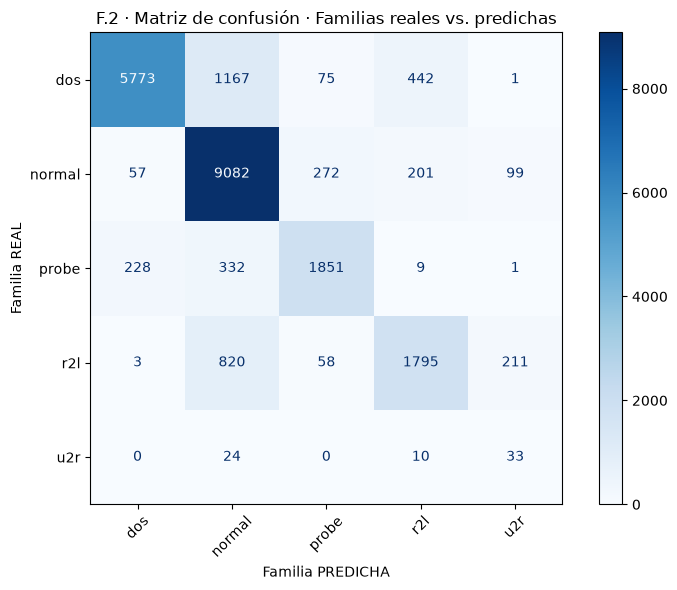

In [40]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Misma función original: asigna a cada conexión una familia de ataque o "normal".
tr, te = add_category(tr), add_category(te)

# Mapeos ausentes indicarían etiquetas desconocidas. No deben tratarse como normales.
for particion, dataframe in [("Entrenamiento", tr), ("Prueba", te)]:
    desconocidas = dataframe.loc[dataframe["category"].isna(), "label"].unique()
    if len(desconocidas):
        raise ValueError(f"{particion}: etiquetas sin categoría conocida: {desconocidas}")

# Reutilizamos columnas y transformaciones del clasificador binario para comparar tareas.
# Se ajustan de nuevo SOLO usando train; las etiquetas de test se usan para evaluar.
modelo_multiclase = make_pipeline(
    clone(preparacion_nsl),
    LogisticRegression(max_iter=3000, class_weight="balanced"),
).fit(tr[atributos_nsl], tr["category"])

prediccion_multiclase = modelo_multiclase.predict(te[atributos_nsl])
reporte_multiclase = classification_report(
    te["category"], prediccion_multiclase, zero_division=0
)

print("=" * 76)
print("F.1 · CLASIFICACIÓN MULTICLASE · Cinco familias de NSL-KDD")
print("=" * 76)
print("Número de ejemplos de cada familia en entrenamiento y prueba:")
display(pd.DataFrame({
    "Entrenamiento (conexiones)": tr["category"].value_counts(),
    "Prueba (conexiones)": te["category"].value_counts(),
}).fillna(0).astype(int).rename_axis("Familia"))
print("\nInforme de test (precision/recall/F1 son proporciones de 0 a 1):")
print(reporte_multiclase)

# Conserva la matriz de confusión original, con encabezados y rotación para leer etiquetas.
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    te["category"], prediccion_multiclase,
    xticks_rotation=45, ax=ax, cmap="Blues", colorbar=True,
)
ax.set(title="F.2 · Matriz de confusión · Familias reales vs. predichas",
       xlabel="Familia PREDICHA", ylabel="Familia REAL")
plt.tight_layout()
plt.show()

### F · Interpretar el informe y la matriz de confusión

**Cómo leer la matriz:** cada **fila** corresponde a la clase *real* y cada **columna** a la clase *predicha*. La **diagonal** recoge aciertos, por ejemplo, `dos` real / `dos` predicho. Una celda fuera de la diagonal revela **confusión entre familias**, como un `r2l` que se predijo `normal`. Los valores son **recuentos**, no porcentajes; las clases con más muestras pueden dominar visualmente. Si una clase tiene poco soporte, una sola conexión puede cambiar mucho su recall.

**Cómo leer el informe:** para cada clase, `precision` responde a «¿cuántas de las alertas de esta familia fueron correctas?», `recall` a «¿cuántas conexiones reales de esta familia se recuperaron?» y `f1-score` resume ambos. `macro avg` promedia las cinco clases **dando el mismo peso a cada una**, por lo que castiga los fallos en ataques raros; `weighted avg` pondera por `support`, por lo que puede quedar alto aunque falle una familia minoritaria. La `accuracy` global puede ocultar un recall deficiente de `u2r` o `r2l`.

**Qué cabe observar y qué no:** en NSL-KDD suelen ser difíciles de distinguir algunas familias `r2l` y `u2r`, por su menor representación, diferencias respecto del train y similitudes con tráfico normal. Si la ejecución muestra recall bajo en esas filas, **esa es la observación**; atribuirlo exactamente a escasez de datos, clases nuevas o solapamiento de atributos es una **hipótesis** que requeriría analizar recuentos, etiquetas nuevas y errores concretos. `class_weight="balanced"` no garantiza resolverlo. El objetivo de un SOC no es maximizar una única media, sino entender **qué incidentes deja escapar y qué alertas consume el equipo**.

---
## Entrega, conclusiones y comprobaciones finales

**Respuesta a la pregunta original: «¿Es 0,5 el umbral óptimo para un SOC?»** No de manera general. Una regresión logística produce **probabilidades estimadas**, pero convertirlas en decisiones exige conocer el coste de **FN** (ataques perdidos), el coste de **FP** (investigaciones innecesarias), la distribución real de ataques y el tiempo disponible del equipo. El ejercicio utiliza el coste ilustrativo `50×FN+FP`: por ello un umbral inferior a 0,5 puede resultar conveniente **en este experimento**, pero debe **seleccionarse en validación**. La sección C.2 muestra explícitamente el error de elegirlo mirando test; la C.3 muestra un procedimiento reproducible que reserva test para la evaluación posterior. El resultado efectivo debe leerse de sus tablas.

**Qué has aprendido:** una regresión lineal puede estimar un comportamiento esperado y convertir residuos en alertas; la logística calcula una probabilidad mediante una sigmoide y optimiza *log-loss*; Naive Bayes clasifica palabras con frecuencias y probabilidades condicionales; k-NN decide a partir de vecinos y es sensible a la distancia; SVM aprende fronteras que pueden ser lineales o flexibles; las métricas multiclase obligan a mirar **cada familia**, no una sola cifra. En todos los casos la prevención de **fugas entre entrenamiento, validación y prueba** es tan importante como el algoritmo.

**Verificación práctica antes de entregar:** reinicia el kernel y ejecuta las celdas en orden; comprueba que se han cargado los dos archivos NSL-KDD auténticos; que en A aparece el día 100 como candidato a anomalía; que en B el log-loss evoluciona según `η`; que en C se distinguen coste en **test de demostración** y coste en **validación**; que en D coinciden los cálculos manuales con scikit-learn; y que en E/F las tablas y las matrices tienen etiquetas interpretables. El experimento de 16 000 flujos (E.3) está **activado** para completar el reto: si resulta demasiado lento, desactívalo y ejecuta de nuevo esa celda. No se guardan resultados sintéticos como si provinieran de NSL-KDD.

El archivo de entrega de esta parte es **`ia4_modelos_didactico.ipynb`**. Su objetivo no es memorizar funciones sino poder explicar **qué aprende el modelo, de dónde sale su predicción, qué limitaciones tiene la evaluación y qué harías de otra forma en un IDS o un SOC real**.